
## 1. Global LightGBM Demand Forecasting

**Purpose.** Train a global machine learning model to predict store-item sales 16 days ahead and compare its performance with the existing forecasting baselines.

**Method.** Use the cleaned and engineered features from Notebook 03. Apply the existing chronological train/validation/test split, train a LightGBM regressor with a log-transformed target, and use validation data for early stopping. Exclude closed-store observations and features identified as potential leakage. Treat categorical features explicitly.

**Output.** A trained LightGBM model, validation and test predictions, and saved model artifacts for subsequent evaluation.

**Limitation.** Initial training uses the development subset rather than the entire Favorita dataset. Sales are used as a proxy for demand, and no hyperparameter tuning is performed on the test set.


In [3]:
import json
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
import lightgbm as lgb
import matplotlib.pyplot as plt
from pathlib import Path

BASE = Path.home() / "Projects/bigdata"
FEAT = BASE / "features"
FIG = BASE / "figures"
RES = BASE / "results"
MOD = BASE / "models"

FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)
MOD.mkdir(exist_ok=True)

defn = json.load(open(FEAT / "subset_definition.json"))
spec = json.load(open(FEAT / "feature_spec.json"))

H = int(defn["horizon_days"])
VAL_START = pd.Timestamp(defn["val_start"])
TEST_START = pd.Timestamp(defn["test_start"])
TRAIN_END = VAL_START - pd.Timedelta(days=1)

print(f"horizon {H} days | train ends {TRAIN_END.date()} | "
      f"validation starts {VAL_START.date()} | test starts {TEST_START.date()}")
print("training filter:", spec["training_filter"])

horizon 16 days | train ends 2017-07-14 | validation starts 2017-07-15 | test starts 2017-07-31
training filter: split == 'train' and is_closed == False



## 2. Load Data and Validate Model Features

**Purpose.** Load the model-ready dataset and verify that the features are suitable for training a global LightGBM forecasting model.

**Method.** Read the Parquet dataset generated by Notebook 03, retrieve the tree-based feature list from `feature_spec.json`, and validate the target, categorical variables, data splits and missing values. Exclude suspected closure days from model training and evaluation.

**Output.** Dataset dimensions, split distribution, feature availability, missing-value summary and leakage checks.

**Limitation.** The dataset contains only the development subset of 10 stores and 607 items. Feature availability checks do not independently prove that every feature is free from temporal leakage.


In [4]:

# 2. Load model-ready data and validate features

FEAT = BASE / "features"
FEATURES = spec["tree_features"]
CATEGORICAL = spec["categorical_features"]
TARGET = spec["target"]

cols = list(dict.fromkeys(
    ["date", "store_nbr", "item_nbr", "split", "is_closed", TARGET]
    + FEATURES
))

df = pd.read_parquet(FEAT / "subset_model.parquet", columns=cols)
df["date"] = pd.to_datetime(df["date"])

print(f"loaded {len(df):,} rows x {len(df.columns)} columns")
print(f"tree features: {len(FEATURES)} | categorical: {len(CATEGORICAL)}")

# 1) Check feature availability and leakage
assert set(FEATURES).issubset(df.columns)
assert set(CATEGORICAL).issubset(FEATURES)
assert not set(FEATURES) & set(spec["analysis_only"] + [TARGET])
assert not df[TARGET].lt(0).any()
assert df["split"].isin(["train", "val", "test"]).all()

# 2) Check the chronological split
dates = df.groupby("split", observed=True)["date"].agg(["min", "max", "count"])
print("\nsplit distribution:")
print(dates.to_string())

assert df.loc[df["split"].eq("train"), "date"].max() < VAL_START
assert df.loc[df["split"].eq("val"), "date"].min() == VAL_START
assert df.loc[df["split"].eq("test"), "date"].min() == TEST_START

# 3) Exclude suspected closure days
closed = df["is_closed"].fillna(True)
print(f"\nsuspected closure rows: {int(closed.sum()):,}")

df = df.loc[~closed].copy()

# 4) Check missing features
missing = df[FEATURES].isna().mean().sort_values(ascending=False)
print("\nfeature missing share:")
print(missing.round(3).to_string())

# 5) Check target distribution
print("\ntarget summary:")
print(df.groupby("split", observed=True)[TARGET]
        .agg(["count", "mean", "median", "max"])
        .round(2).to_string())

print("\nfeature validation passed")


loaded 5,888,022 rows x 28 columns
tree features: 22 | categorical: 7

split distribution:
             min        max    count
split                               
train 2013-01-02 2017-07-14  5732606
val   2017-07-15 2017-07-30    77601
test  2017-07-31 2017-08-15    77815

suspected closure rows: 52,605

feature missing share:
promo_rate_observed_28    0.456
lag_364                   0.296
lag_28                    0.030
zero_share_28             0.026
roll_mean_28              0.026
lag_21                    0.024
lag_16                    0.020
roll_mean_7               0.017
oil_lag16                 0.005
city_code                 0.000
month                     0.000
family_code               0.000
cluster                   0.000
perishable                0.000
is_payday                 0.000
is_workday_swap           0.000
is_holiday                0.000
hol_local                 0.000
hol_national              0.000
store_type_code           0.000
state_code                0.


## 3. Prepare Training Data

**Purpose.** Prepare the chronological training, validation and test datasets for global LightGBM forecasting.

**Method.** Use the existing time-based splits, sample up to 1.5 million training observations for the initial experiment, and convert the seven categorical features to pandas categorical dtype. Category definitions are learned from training data only. Missing numerical values are preserved for LightGBM's native missing-value handling.

**Output.** Training, validation and test feature matrices with consistent categorical encoding and log-transformed training targets.

**Limitation.** Random sampling reduces computational cost but may underrepresent rare demand patterns. The initial model will be retrained on more observations if the experiment is successful.


In [5]:

# 3. Prepare training, validation and test data

MAX_TRAIN = 1_500_000
SEED = 42

train = df.loc[df["split"].eq("train")].copy()
val = df.loc[df["split"].eq("val")].copy()
test = df.loc[df["split"].eq("test")].copy()

# sample training rows only; keep validation and test complete
if len(train) > MAX_TRAIN:
    train = train.sample(n=MAX_TRAIN, random_state=SEED)
    train = train.sort_values(["date", "store_nbr", "item_nbr"])

# use category values observed in training only
for c in CATEGORICAL:
    cats = sorted(train.loc[train[c].ge(0), c].dropna().unique().tolist())

    for part in (train, val, test):
        part[c] = pd.Categorical(
            part[c].where(part[c].ge(0)),
            categories=cats
        )

# LightGBM handles missing numerical values directly
X_train = train[FEATURES]
X_val = val[FEATURES]
X_test = test[FEATURES]

y_train = np.log1p(train[TARGET].to_numpy(dtype="float32"))
y_val = np.log1p(val[TARGET].to_numpy(dtype="float32"))
y_test = test[TARGET].to_numpy(dtype="float32")

assert X_train.columns.equals(X_val.columns)
assert X_train.columns.equals(X_test.columns)
assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

print(f"train: {X_train.shape[0]:,} rows x {X_train.shape[1]} features")
print(f"validation: {X_val.shape[0]:,} rows")
print(f"test: {X_test.shape[0]:,} rows")
print(f"categorical features: {len(CATEGORICAL)}")

print("\nmissing categories:")
for c in CATEGORICAL:
    print(f"{c}: train={X_train[c].isna().sum():,}, "
          f"val={X_val[c].isna().sum():,}, "
          f"test={X_test[c].isna().sum():,}")

print("\ntraining data ready")


train: 1,500,000 rows x 22 features
validation: 77,601 rows
test: 77,815 rows
categorical features: 7

missing categories:
family_code: train=0, val=0, test=0
city_code: train=0, val=0, test=0
state_code: train=0, val=0, test=0
store_type_code: train=0, val=0, test=0
cluster: train=0, val=0, test=0
dow: train=0, val=0, test=0
month: train=0, val=0, test=0

training data ready



## 4. Train Global LightGBM Model

**Purpose.** Train a global machine learning model to forecast daily store-item sales 16 days ahead.

**Method.** Fit a LightGBM regressor using the engineered time-series and categorical features. Apply a log1p transformation to the target to reduce sales skewness. Use the validation period for early stopping, with a maximum of 1,000 boosting iterations.

**Output.** A trained LightGBM model, its optimal boosting iteration, and validation predictions.

**Limitation.** The initial model uses a sampled training dataset of 1.5 million observations. Early stopping optimizes RMSE on log-transformed sales rather than the final RMSSE metric.


In [6]:

# 4. Train global LightGBM model

import lightgbm as lgb
import time

t0 = time.time()

model = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=100,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=SEED,
    n_jobs=4,
    verbosity=-1
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    eval_metric="rmse",
    categorical_feature=CATEGORICAL,
    callbacks=[
        lgb.early_stopping(50, verbose=True),
        lgb.log_evaluation(100)
    ]
)

elapsed = time.time() - t0

print(f"\ntraining time: {elapsed:.1f} seconds")
print(f"best iteration: {model.best_iteration_}")

# predict validation and test sales
val_pred = np.maximum(
    np.expm1(model.predict(X_val)), 0
)
test_pred = np.maximum(
    np.expm1(model.predict(X_test)), 0
)

print(f"\nvalidation predictions: {len(val_pred):,}")
print(f"test predictions: {len(test_pred):,}")
print(f"validation predicted mean: {val_pred.mean():.3f}")
print(f"test predicted mean: {test_pred.mean():.3f}")

assert np.isfinite(val_pred).all()
assert np.isfinite(test_pred).all()
assert (val_pred >= 0).all()
assert (test_pred >= 0).all()

print("\nmodel training completed")


Training until validation scores don't improve for 50 rounds
[100]	valid_0's rmse: 0.636073	valid_0's l2: 0.404589
[200]	valid_0's rmse: 0.633165	valid_0's l2: 0.400898
Early stopping, best iteration is:
[242]	valid_0's rmse: 0.632802	valid_0's l2: 0.400439

training time: 4.4 seconds
best iteration: 242

validation predictions: 77,601
test predictions: 77,815
validation predicted mean: 4.164
test predicted mean: 4.025

model training completed



## 5. Evaluate LightGBM Against the Baseline

**Purpose.** Evaluate the global LightGBM model against the moving-average baseline using the forecasting metrics established in Notebook 05.

**Method.** Calculate RMSSE using the mean squared one-day differences from the training period. Retain active store-item series with valid historical scales and complete validation/test observations. Compare LightGBM and moving_avg_28 on identical series and dates, reporting mean series-level RMSSE, WAPE and forecast bias.

**Output.** Validation and test performance tables, percentage RMSSE improvement over the baseline, and evaluation coverage.

**Limitation.** Results are based on the development subset and one validation/test block. The model was selected using validation log-RMSE rather than RMSSE. Performance may differ across other forecasting periods and the full 54-store dataset.


In [7]:

# 5. Evaluate LightGBM against moving_avg_28

MIN_DIFFS = 30

# load historical sales for RMSSE scaling
hist = pd.read_parquet(
    FEAT / "subset_model.parquet",
    columns=["date", "store_nbr", "item_nbr",
             "split", "is_closed", TARGET]
)
hist["date"] = pd.to_datetime(hist["date"])
hist.loc[hist["is_closed"], TARGET] = np.nan

# compute scale from consecutive training observations
hist = hist.sort_values(["store_nbr", "item_nbr", "date"])
hist["prev_sales"] = hist.groupby(
    ["store_nbr", "item_nbr"]
)[TARGET].shift(1)
hist["prev_date"] = hist.groupby(
    ["store_nbr", "item_nbr"]
)["date"].shift(1)

valid_diff = (
    hist["split"].eq("train")
    & hist["date"].sub(hist["prev_date"]).eq(pd.Timedelta(days=1))
    & hist[TARGET].notna()
    & hist["prev_sales"].notna()
)

hist["sq_diff"] = np.where(
    valid_diff,
    (hist[TARGET] - hist["prev_sales"]) ** 2,
    np.nan
)

scale = hist.groupby(
    ["store_nbr", "item_nbr"]
)["sq_diff"].agg(["mean", "count"]).reset_index()

scale["mean"] = scale["mean"].where(
    (scale["count"] >= MIN_DIFFS) & (scale["mean"] > 0)
)

# active series: sales in the 90 days before test starts
active = hist.loc[
    (hist["date"] >= TEST_START - pd.Timedelta(days=90))
    & (hist["date"] < TEST_START)
].groupby(["store_nbr", "item_nbr"])[TARGET].max().gt(0)

active = active.rename("active_test").reset_index()

# load baseline predictions from existing engineered features
base = pd.read_parquet(
    FEAT / "subset_model.parquet",
    columns=["date", "store_nbr", "item_nbr", "roll_mean_28"]
)
base["date"] = pd.to_datetime(base["date"])

def evaluate(part, pred, split):
    t = part[["date", "store_nbr", "item_nbr", TARGET]].copy()
    t["lightgbm"] = pred
    t = t.merge(base, on=["date", "store_nbr", "item_nbr"], how="left")
    t = t.merge(scale[["store_nbr", "item_nbr", "mean"]],
                on=["store_nbr", "item_nbr"], how="left")
    t = t.merge(active, on=["store_nbr", "item_nbr"], how="left")

    t = t[
        t["active_test"].eq(True)
        & t["mean"].notna()
        & t["roll_mean_28"].notna()
    ].copy()

    # require complete observations for each evaluated series
    counts = t.groupby(["store_nbr", "item_nbr"])["date"].nunique()
    complete = counts[counts == H].index
    t = t.set_index(["store_nbr", "item_nbr"]).loc[complete].reset_index()

    rows = []
    for name, col in [("moving_avg_28", "roll_mean_28"),
                      ("lightgbm", "lightgbm")]:
        err = t[col] - t[TARGET]
        t["sq_error"] = err ** 2

        series = t.groupby(["store_nbr", "item_nbr"]).agg(
            mse=("sq_error", "mean"),
            scale=("mean", "first")
        )
        rmsse = np.sqrt(series["mse"] / series["scale"]).mean()
        wape = err.abs().sum() / t[TARGET].sum()
        bias = err.sum() / t[TARGET].sum()
        rows.append((split, name, rmsse, wape, bias))

    print(f"{split}: {len(t):,} rows | "
          f"{t.groupby(['store_nbr', 'item_nbr']).ngroups:,} series")
    return rows

rows = evaluate(val, val_pred, "val")
rows += evaluate(test, test_pred, "test")

metrics = pd.DataFrame(
    rows, columns=["split", "model", "rmsse", "wape", "bias"]
)

print("\nforecast evaluation:")
print(metrics.round(4).to_string(index=False))

test_scores = metrics[metrics["split"] == "test"].set_index("model")
baseline_rmsse = test_scores.loc["moving_avg_28", "rmsse"]
model_rmsse = test_scores.loc["lightgbm", "rmsse"]

improvement = (baseline_rmsse - model_rmsse) / baseline_rmsse * 100

print(f"\ntest RMSSE improvement: {improvement:+.2f}%")

metrics.to_csv(RES / "lightgbm_vs_baseline.csv", index=False)


val: 69,520 rows | 4,345 series
test: 69,520 rows | 4,345 series

forecast evaluation:
split         model  rmsse   wape    bias
  val moving_avg_28 0.7670 0.6193  0.0206
  val      lightgbm 0.7314 0.5395 -0.2454
 test moving_avg_28 0.7554 0.5879  0.0684
 test      lightgbm 0.7298 0.5209 -0.2318

test RMSSE improvement: +3.39%



## 6. Validation-Based Bias Correction

**Purpose.** Reduce systematic underforecasting in LightGBM predictions.

**Method.** Estimate a multiplicative correction factor using validation actual and predicted sales. Apply the factor to validation and test predictions, without using test actuals to determine the factor.

**Output.** Bias-corrected predictions and preliminary aggregate WAPE and bias metrics.

**Limitation.** The correction factor is calibrated on the validation period and may not generalize to future periods. Validation metrics after calibration are in-sample diagnostics, not independent evaluation results.


In [8]:

# 6. Calibrate forecast bias using validation data

val_actual = val[TARGET].to_numpy(dtype="float64")
test_actual = test[TARGET].to_numpy(dtype="float64")

correction = val_actual.sum() / val_pred.sum()

val_pred_corrected = np.maximum(val_pred * correction, 0)
test_pred_corrected = np.maximum(test_pred * correction, 0)

print(f"correction factor: {correction:.4f}")

for name, actual, pred in [
    ("validation", val_actual, val_pred_corrected),
    ("test", test_actual, test_pred_corrected)
]:
    wape = np.abs(pred - actual).sum() / actual.sum()
    bias = (pred - actual).sum() / actual.sum()

    print(f"{name}: WAPE={wape:.4f} | bias={bias:+.4f}")


correction factor: 1.3219
validation: WAPE=0.5660 | bias=-0.0000
test: WAPE=0.5450 | bias=+0.0153



## 7. Compare Original and Bias-Corrected LightGBM

**Purpose.** Determine whether validation-based bias correction improves overall forecasting performance.

**Method.** Evaluate corrected predictions using the same active-series selection, RMSSE scaling and forecast dates as the original LightGBM and moving-average baseline.

**Output.** A consistent comparison of RMSSE, WAPE and forecast bias across three forecasting approaches.

**Limitation.** The correction factor was estimated using validation actuals. Test results provide the primary out-of-sample assessment of the correction.


In [9]:

# 7. Compare original and corrected forecasts

corrected_rows = evaluate(
    val, val_pred_corrected, "val"
)
corrected_rows += evaluate(
    test, test_pred_corrected, "test"
)

corrected_metrics = pd.DataFrame(
    corrected_rows,
    columns=["split", "model", "rmsse", "wape", "bias"]
)

corrected_metrics = corrected_metrics.loc[
    corrected_metrics["model"].eq("lightgbm")
].copy()

corrected_metrics["model"] = "lightgbm_corrected"

comparison = pd.concat(
    [metrics, corrected_metrics],
    ignore_index=True
)

print("\nModel comparison:")
print(comparison.round(4).to_string(index=False))

# compare test RMSSE against the baseline
test_scores = comparison.loc[
    comparison["split"].eq("test")
].set_index("model")

baseline_score = test_scores.loc["moving_avg_28", "rmsse"]

print("\nTest RMSSE improvement vs baseline:")
for name in ["lightgbm", "lightgbm_corrected"]:
    score = test_scores.loc[name, "rmsse"]
    improvement = (baseline_score - score) / baseline_score * 100
    print(f"{name}: {improvement:+.2f}%")

comparison.to_csv(
    RES / "lightgbm_model_comparison.csv",
    index=False
)


val: 69,520 rows | 4,345 series
test: 69,520 rows | 4,345 series

Model comparison:
split              model  rmsse   wape    bias
  val      moving_avg_28 0.7670 0.6193  0.0206
  val           lightgbm 0.7314 0.5395 -0.2454
 test      moving_avg_28 0.7554 0.5879  0.0684
 test           lightgbm 0.7298 0.5209 -0.2318
  val lightgbm_corrected 0.7434 0.5623 -0.0024
 test lightgbm_corrected 0.7377 0.5400  0.0155

Test RMSSE improvement vs baseline:
lightgbm: +3.39%
lightgbm_corrected: +2.33%



## 8. Feature Importance Analysis

**Purpose.** Identify the most influential features in the global LightGBM forecasting model.

**Method.** Extract gain-based and split-based feature importance from the trained model. Rank the features by total information gain across the decision trees.

**Output.** A ranked feature importance table for interpreting model behavior.

**Limitation.** Feature importance measures contribution within the fitted model, not causal relationships. Correlated features may share importance.


In [10]:

# 8.1 Extract LightGBM feature importance

booster = model.booster_

importance = pd.DataFrame({
    "feature": booster.feature_name(),
    "gain": booster.feature_importance(importance_type="gain"),
    "split": booster.feature_importance(importance_type="split")
})

importance["gain_pct"] = (
    importance["gain"] / importance["gain"].sum() * 100
)

importance = importance.sort_values(
    "gain", ascending=False
).reset_index(drop=True)

print("Top 15 features by information gain:")
print(importance.head(15).round(2).to_string(index=False))

importance.to_csv(
    RES / "lightgbm_feature_importance.csv",
    index=False
)


Top 15 features by information gain:
               feature       gain  split  gain_pct
          roll_mean_28 5264927.85    605     40.03
           roll_mean_7 5111584.90    578     38.86
         zero_share_28 1019277.64    480      7.75
                lag_28  337141.23    249      2.56
                lag_16  226845.46    340      1.72
                lag_21  208599.79    229      1.59
           family_code  207326.61   1042      1.58
               lag_364  189064.62    578      1.44
             oil_lag16  184271.46    887      1.40
                 month  163855.86    910      1.25
                   dow  133515.08    476      1.02
               cluster   38610.46    301      0.29
       store_type_code   28088.69    184      0.21
promo_rate_observed_28   26583.54    197      0.20
          hol_national    6134.51     70      0.05



### 8.2 Visualize Feature Importance

**Purpose.** Visualize the most influential predictors in the global LightGBM model.

**Method.** Rank the top 15 features by gain-based importance and display their percentage contributions in a horizontal bar chart.

**Output.** A feature importance figure saved for reporting and interpretation.

**Limitation.** Gain-based importance reflects the fitted model's decision trees and does not establish causal effects.


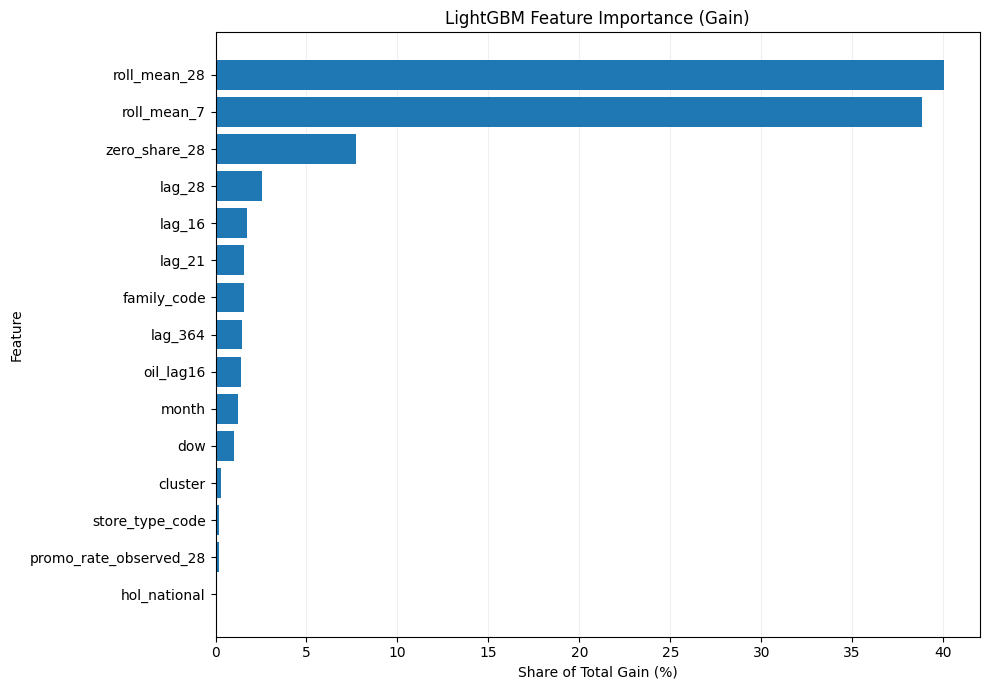

In [11]:

# 8.2 Plot top 15 feature importance

import matplotlib.pyplot as plt

top15 = importance.head(15).sort_values("gain_pct")

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    top15["feature"],
    top15["gain_pct"]
)

ax.set_title("LightGBM Feature Importance (Gain)")
ax.set_xlabel("Share of Total Gain (%)")
ax.set_ylabel("Feature")

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

FIG.mkdir(parents=True, exist_ok=True)
plt.savefig(
    FIG / "lightgbm_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



## 9. Temporal Leakage Audit

**Purpose.** Verify that sales-based features respect the 16-day forecasting horizon.

**Method.** Inspect the feature engineering logic from Notebook 03, focusing on lagged and rolling sales features.

**Output.** Source code used to construct the historical sales features.

**Limitation.** Reviewing feature definitions is the first audit step. Numerical verification will follow if needed.


In [12]:

# 9.1 Inspect historical feature engineering code

import json

notebooks = sorted(BASE.rglob("03*.ipynb"))

if not notebooks:
    print("Notebook 03 not found under BASE.")
else:
    print("Notebook:", notebooks[0])

    nb = json.loads(notebooks[0].read_text())

    keywords = [
        "roll_mean_7",
        "roll_mean_28",
        "zero_share_28",
        "lag_16"
    ]

    for i, cell in enumerate(nb["cells"]):
        if cell["cell_type"] != "code":
            continue

        source = "".join(cell["source"])

        if any(k in source for k in keywords):
            print(f"\n--- Cell {i} ---")
            print(source[:4000])


Notebook: /Users/tinnguyen/Projects/bigdata/notebooks/.ipynb_checkpoints/03_features-checkpoint.ipynb

--- Cell 6 ---
import numpy as np
import pandas as pd
from pathlib import Path

BASE = Path.home() / "Projects/bigdata"
H = 16                    # forecast horizon (days)
LAGS = [16, 21, 28, 364]  # every lag >= H
WINDOWS = [7, 28]

df = pd.read_parquet(BASE / "features" / "subset_step1.parquet")
df = df.sort_values(["store_nbr", "item_nbr", "date"]).reset_index(drop=True)
n_rows = len(df)

# day x series matrix on the true calendar
all_days = pd.date_range(df["date"].min(), df["date"].max())
d_idx = all_days.get_indexer(df["date"])
key = df["store_nbr"].astype("int64") * 10_000_000 + df["item_nbr"].astype("int64")
s_codes, s_uniq = pd.factorize(key, sort=True)

obs = df["unit_sales"].to_numpy(dtype="float32").copy()
obs[df["is_closed"].to_numpy()] = np.nan          # no-record days are not demand
Y = np.full((len(all_days), len(s_uniq)), np.nan, dtype="float32")
Y[d_idx, s_codes] = 


### 9.2 Audit External Feature Construction

**Purpose.** Verify that promotion-history and oil-price features do not use information unavailable at the forecast origin.

**Method.** Inspect the feature engineering source code for temporal shifts, rolling windows and missing-value handling.

**Output.** Source definitions of the external features.

**Limitation.** Source inspection does not independently verify that real-world external data would be published by the forecast origin.


In [13]:

# 9.2 Inspect external feature construction

import json

nb_path = BASE / "notebooks" / "03_features.ipynb"
nb = json.loads(nb_path.read_text())

keywords = ["promo_rate_observed_28", "oil_lag16"]

for i, cell in enumerate(nb["cells"]):
    if cell["cell_type"] != "code":
        continue

    lines = "".join(cell["source"]).splitlines()

    for j, line in enumerate(lines):
        if any(k in line for k in keywords):
            start = max(0, j - 5)
            end = min(len(lines), j + 6)

            print(f"\n--- Cell {i}, line {j + 1} ---")
            print("\n".join(lines[start:end]))



--- Cell 8, line 29 ---
promo = df["onpromotion"].to_numpy().astype("float32")
promo[promo < 0] = np.nan
P = np.full((len(all_days), s_codes.max() + 1), np.nan, dtype="float32")
P[d_idx, s_codes] = promo
share = pd.DataFrame(P).shift(H).rolling(28, min_periods=14).mean()
df["promo_rate_observed_28"] = share.to_numpy(dtype="float32")[d_idx, s_codes]

df = df.drop(columns=["promo", "promo_known"], errors="ignore")
assert len(df) == n_rows

print("\npromo_rate_observed_28 missing by split:")

--- Cell 8, line 34 ---
df["promo_rate_observed_28"] = share.to_numpy(dtype="float32")[d_idx, s_codes]

df = df.drop(columns=["promo", "promo_known"], errors="ignore")
assert len(df) == n_rows

print("\npromo_rate_observed_28 missing by split:")
print(df.groupby("split", observed=True)["promo_rate_observed_28"].apply(lambda s: s.isna().mean()).round(3))

df.to_parquet(BASE / "features" / "subset_features.parquet", index=False)
print(f"\nsaved subset_features.parquet: {df.shape[0]:,} rows x {df.shape


### 9.3 Verify Oil Price Feature

**Purpose.** Verify that the oil-price feature respects the 16-day forecasting horizon.

**Method.** Inspect the oil-price transformation logic in the data preparation and feature engineering notebooks.

**Output.** Source code showing how `oil_lag16` is constructed.

**Limitation.** A temporal shift ensures historical alignment but does not independently establish real-world data publication timing.


In [15]:

# 9.3 Inspect oil-price feature construction

for path in sorted((BASE / "notebooks").glob("0[1-3]*.ipynb")):
    nb = json.loads(path.read_text())

    for i, cell in enumerate(nb["cells"]):
        if cell["cell_type"] != "code":
            continue

        lines = "".join(cell["source"]).splitlines()

        for j, line in enumerate(lines):
            if "oil_lag16" in line or "shift(16)" in line:
                start = max(0, j - 5)
                end = min(len(lines), j + 6)

                print(f"\n--- {path.name} | Cell {i} ---")
                print("\n".join(lines[start:end]))



--- 03_features.ipynb | Cell 10 ---
                 "earthquake", "is_event_other"]
CAT_COLS = ["family", "city", "state", "store_type"]
FLAG_COLS = ["hol_national", "hol_local", "is_holiday", "is_workday_swap", "is_payday"]
INT_COLS = ["perishable", "cluster", "dow", "month"]
SALES_COLS = ["lag_16", "lag_21", "lag_28", "lag_364", "roll_mean_7", "roll_mean_28"]
OTHER_NUM = ["zero_share_28", "promo_rate_observed_28", "oil_lag16"]

# rows used to learn encodings and scaling: train split, store open
fit = df["split"].eq("train") & ~df["is_closed"]
print(f"fit rows (train, not closed): {int(fit.sum()):,} of {n_rows:,}")


--- 03_features.ipynb | Cell 10 ---

# 4) explicit feature lists
# categorical columns: integer codes are labels, not quantities
CATEGORICAL = [c + "_code" for c in CAT_COLS] + ["cluster", "dow", "month"]
tree_features = ([c + "_code" for c in CAT_COLS] + FLAG_COLS + INT_COLS
                 + SALES_COLS + ["zero_share_28", "promo_rate_observed_28", "oil_lag16"])
# lin

In [16]:

# 9.4 Inspect oil-price processing across notebooks

import json

for path in sorted((BASE / "notebooks").glob("0[1-3]*.ipynb")):
    nb = json.loads(path.read_text())

    for i, cell in enumerate(nb["cells"]):
        if cell["cell_type"] != "code":
            continue

        source = "".join(cell["source"])
        lines = source.splitlines()

        oil_lines = [
            j for j, line in enumerate(lines)
            if "oil" in line.lower() or "dcoilwtico" in line.lower()
        ]

        if not oil_lines:
            continue

        # show surrounding lines without repeating overlapping sections
        selected = set()
        for j in oil_lines:
            selected.update(range(max(0, j - 6), min(len(lines), j + 7)))

        print(f"\n--- {path.name} | Cell {i} ---")

        for j in sorted(selected):
            print(f"{j + 1:03d}: {lines[j]}")



--- 01_load_and_profile.ipynb | Cell 2 ---
002: from pathlib import Path
003: 
004: BASE = Path.home() / "Projects/bigdata"
005: RAW = BASE / "raw"
006: 
007: tables = {}
008: for name in ["stores", "items", "oil", "holidays_events", "transactions"]:
009:     df = pd.read_csv(RAW / f"{name}.csv")
010:     tables[name] = df
011:     print(f"\n=== {name}: {df.shape[0]:,} rows x {df.shape[1]} cols ===")
012:     print(df.dtypes.to_string())
013:     nulls = df.isna().sum()
014:     print("nulls:", nulls[nulls > 0].to_dict() if (nulls > 0).any() else "none")

--- 02_cleaning_and_join.ipynb | Cell 9 ---
001: RAW = BASE / "raw"
002: DIM = BASE / "clean" / "dim"
003: DIM.mkdir(parents=True, exist_ok=True)
004: days = pd.to_datetime(dates)
005: 
006: oil = pd.read_csv(RAW / "oil.csv", parse_dates=["date"]).set_index("date")["dcoilwtico"]
007: print("oil rows:", len(oil), "| null:", int(oil.isna().sum()))
008: oil = oil.reindex(days)
009: print("oil after reindex to", len(days), "sales days | 


## 10. Prepare Time-Safe Evaluation Splits

**Purpose.** Align model training and validation with the 16-day forecasting horizon.

**Method.** Use training observations available before the earliest validation forecast origin. Select the model using June validation, then reserve data through July 14 for final training before the July 31 test period.

**Output.** Development training, validation and final training datasets with temporally consistent cutoffs.

**Limitation.** The July–August test period has already been inspected during earlier experiments and should not be described as an untouched holdout.


In [17]:

# 10. Prepare time-safe evaluation splits

DEV_TRAIN_END = pd.Timestamp("2017-05-30")
DEV_VAL_START = pd.Timestamp("2017-06-15")
DEV_VAL_END = pd.Timestamp("2017-06-30")
FINAL_TRAIN_END = pd.Timestamp("2017-07-14")

# development training: data available before validation origin
dev_train = df.loc[
    df["date"].le(DEV_TRAIN_END)
].copy()

# development validation: independent 16-day period
dev_val = df.loc[
    df["date"].between(DEV_VAL_START, DEV_VAL_END)
].copy()

# final training: data available before first test origin
final_train = df.loc[
    df["date"].le(FINAL_TRAIN_END)
].copy()

assert DEV_TRAIN_END <= DEV_VAL_START - pd.Timedelta(days=H)
assert FINAL_TRAIN_END <= TEST_START - pd.Timedelta(days=H)

print(f"development train: {len(dev_train):,} rows")
print(f"development validation: {len(dev_val):,} rows")
print(f"final training: {len(final_train):,} rows")
print(f"test: {len(test):,} rows")

print("\nTemporal split checks passed")


development train: 5,462,910 rows
development validation: 77,238 rows
final training: 5,680,001 rows
test: 77,815 rows

Temporal split checks passed



## 11. Train LightGBM with Time-Safe Validation

**Purpose.** Select LightGBM's optimal boosting iteration without using observations unavailable at the validation forecast origin.

**Method.** Train on sales through May 30, 2017, and validate on June 15–30, 2017. Sample up to 1.5 million training observations, learn categorical values from development training data only, and apply early stopping using log-scale RMSE.

**Output.** A development LightGBM model and its best boosting iteration.

**Limitation.** The development model uses sampled training observations and optimizes log-RMSE rather than RMSSE. Its selected iteration will be reused for final model training.


In [18]:

# 11.1 Prepare development training data

MAX_TRAIN = 1_500_000
SEED = 42

dev_sample = dev_train.sample(
    n=min(MAX_TRAIN, len(dev_train)),
    random_state=SEED
)

# learn categorical values from development training only
dev_categories = {}

for c in CATEGORICAL:
    dev_categories[c] = sorted(
        dev_train.loc[dev_train[c] >= 0, c]
        .dropna().unique().tolist()
    )

def make_features(part, categories):
    X = part[FEATURES].copy()

    for c in CATEGORICAL:
        X[c] = pd.Categorical(
            X[c].where(X[c] >= 0),
            categories=categories[c]
        )

    return X

X_dev = make_features(dev_sample, dev_categories)
X_dev_val = make_features(dev_val, dev_categories)

y_dev = np.log1p(dev_sample[TARGET].to_numpy(dtype="float32"))
y_dev_val = np.log1p(dev_val[TARGET].to_numpy(dtype="float32"))

print(f"development training: {X_dev.shape}")
print(f"development validation: {X_dev_val.shape}")
print(f"categorical features: {len(CATEGORICAL)}")

assert X_dev.columns.equals(X_dev_val.columns)
assert dev_train["date"].max() <= DEV_VAL_START - pd.Timedelta(days=H)

print("\ndevelopment data ready")


development training: (1500000, 22)
development validation: (77238, 22)
categorical features: 7

development data ready


In [19]:

# 11.2 Train LightGBM with June validation

import lightgbm as lgb
import time

t0 = time.time()

dev_model = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=100,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=SEED,
    n_jobs=4,
    verbosity=-1
)

dev_model.fit(
    X_dev,
    y_dev,
    eval_set=[(X_dev_val, y_dev_val)],
    eval_metric="rmse",
    categorical_feature=CATEGORICAL,
    callbacks=[
        lgb.early_stopping(50, verbose=True),
        lgb.log_evaluation(100)
    ]
)

dev_best_iter = dev_model.best_iteration_

print(f"\ntraining time: {time.time() - t0:.1f} seconds")
print(f"best iteration: {dev_best_iter}")
print(f"validation log-RMSE: {dev_model.best_score_['valid_0']['rmse']:.4f}")

print("\ndevelopment model completed")


Training until validation scores don't improve for 50 rounds
[100]	valid_0's rmse: 0.65399	valid_0's l2: 0.427703
[200]	valid_0's rmse: 0.649121	valid_0's l2: 0.421358
[300]	valid_0's rmse: 0.647758	valid_0's l2: 0.419591
[400]	valid_0's rmse: 0.647472	valid_0's l2: 0.41922
[500]	valid_0's rmse: 0.647433	valid_0's l2: 0.419169
Early stopping, best iteration is:
[463]	valid_0's rmse: 0.647311	valid_0's l2: 0.419012

training time: 7.5 seconds
best iteration: 463
validation log-RMSE: 0.6473

development model completed



## 12. Train Final LightGBM Model

**Purpose.** Train the final forecasting model using the boosting iteration selected from time-safe development validation.

**Method.** Sample up to 1.5 million observations from the final training period ending July 14, 2017. Refit categorical encodings on the final training period, train LightGBM with 463 boosting iterations, and generate 16-day-ahead test predictions.

**Output.** Final trained LightGBM model and test predictions.

**Limitation.** The model uses sampled training observations. The July–August test block has already been examined in earlier experiments and is not an untouched holdout.


In [21]:

# 12.1 Prepare final training data

import numpy as np
import pandas as pd

MAX_TRAIN = 1_500_000
SEED = 42

# sample final training data
final_sample = final_train.sample(
    n=min(MAX_TRAIN, len(final_train)),
    random_state=SEED
)

# learn categories from final training only
final_categories = {}

for c in CATEGORICAL:
    values = pd.to_numeric(
        final_train[c].astype("object"),
        errors="coerce"
    )

    final_categories[c] = sorted(
        values[values >= 0].dropna().unique().tolist()
    )

# convert categorical features safely
def make_features(part, categories):
    X = part[FEATURES].copy()

    for c in CATEGORICAL:
        codes = pd.to_numeric(
            X[c].astype("object"),
            errors="coerce"
        )

        X[c] = pd.Categorical(
            codes.where(codes >= 0),
            categories=categories[c]
        )

    return X

# prepare feature matrices
X_final = make_features(final_sample, final_categories)
X_test_final = make_features(test, final_categories)

# log-transform target
y_final = np.log1p(
    final_sample[TARGET].to_numpy(dtype="float32")
)

# validation checks
assert X_final.columns.equals(X_test_final.columns)
assert len(X_final) == len(y_final)
assert final_train["date"].max() <= (
    test["date"].min() - pd.Timedelta(days=H)
)

print(f"final training: {X_final.shape}")
print(f"test: {X_test_final.shape}")
print(f"categorical features: {len(CATEGORICAL)}")
print(f"selected iterations: {dev_best_iter}")

print("\nfinal training data ready")


final training: (1500000, 22)
test: (77815, 22)
categorical features: 7
selected iterations: 463

final training data ready


In [22]:

# 12.2 Train final LightGBM model

import lightgbm as lgb
import time

t0 = time.time()

# reuse development hyperparameters
final_params = dev_model.get_params().copy()
final_params["n_estimators"] = int(dev_best_iter)

final_model = lgb.LGBMRegressor(**final_params)

# train final model
final_model.fit(
    X_final,
    y_final,
    categorical_feature=CATEGORICAL
)

elapsed = time.time() - t0

print(f"training time: {elapsed:.1f} seconds")
print(f"boosting iterations: {final_model.n_estimators_}")

# generate test predictions
final_test_pred = np.maximum(
    np.expm1(final_model.predict(X_test_final)),
    0
)

# validate predictions
assert len(final_test_pred) == len(test)
assert np.isfinite(final_test_pred).all()
assert (final_test_pred >= 0).all()

print(f"\ntest predictions: {len(final_test_pred):,}")
print(f"predicted mean: {final_test_pred.mean():.3f}")

print("\nfinal model training completed")


training time: 6.8 seconds
boosting iterations: 463

test predictions: 77,815
predicted mean: 4.089

final model training completed



## 13. Final Model Evaluation

**Purpose.** Evaluate the final LightGBM model against the moving-average baseline using a temporally consistent test protocol.

**Method.** Identify active store-item series using the 90 days preceding the earliest test forecast origin. Use training-only RMSSE scales and evaluate complete 16-day test series. Compare LightGBM and moving_avg_28 using RMSSE, WAPE and forecast bias.

**Output.** Test evaluation coverage, model comparison and RMSSE improvement.

**Limitation.** Results represent the development subset of 10 stores. The test period has been examined during previous experiments and is not a completely untouched holdout.


In [23]:

# 13.1 Prepare final evaluation dataset

ORIGIN = TEST_START - pd.Timedelta(days=H)
ACTIVE_DAYS = 90

# identify active series before the first test forecast origin
active_final = hist.loc[
    hist["date"].ge(ORIGIN - pd.Timedelta(days=ACTIVE_DAYS))
    & hist["date"].lt(ORIGIN)
].groupby(["store_nbr", "item_nbr"])[TARGET].max().gt(0)

active_final = active_final.rename("active").reset_index()

# align predictions with test observations
eval_final = test[
    ["date", "store_nbr", "item_nbr", TARGET, "roll_mean_28"]
].copy()

eval_final["lightgbm"] = final_test_pred

# merge training-only RMSSE scales and active status
eval_final = eval_final.merge(
    scale[["store_nbr", "item_nbr", "mean"]],
    on=["store_nbr", "item_nbr"],
    how="left"
)

eval_final = eval_final.merge(
    active_final,
    on=["store_nbr", "item_nbr"],
    how="left"
)

# retain eligible series
eval_final = eval_final.loc[
    eval_final["active"].eq(True)
    & eval_final["mean"].gt(0)
    & eval_final["roll_mean_28"].notna()
    & eval_final[TARGET].notna()
].copy()

# require all 16 test dates per series
keys = ["store_nbr", "item_nbr"]
counts = eval_final.groupby(keys)["date"].nunique()
complete = counts[counts.eq(H)].index

eval_final = eval_final.set_index(keys)
eval_final = eval_final.loc[
    eval_final.index.isin(complete)
].reset_index()

assert eval_final.groupby(keys)["date"].nunique().eq(H).all()
assert eval_final["lightgbm"].notna().all()

print(f"forecast origin: {ORIGIN.date()}")
print(f"test rows evaluated: {len(eval_final):,}")
print(f"active series evaluated: {eval_final.groupby(keys).ngroups:,}")
print(f"forecast horizon: {H} days")

print("\nfinal evaluation data ready")


forecast origin: 2017-07-15
test rows evaluated: 70,048
active series evaluated: 4,378
forecast horizon: 16 days

final evaluation data ready


In [24]:

# 13.2 Calculate final forecasting metrics

rows = []

for name, col in [
    ("moving_avg_28", "roll_mean_28"),
    ("lightgbm_final", "lightgbm")
]:
    error = eval_final[col] - eval_final[TARGET]

    squared_error = error.pow(2)

    series_mse = squared_error.groupby(
        [eval_final["store_nbr"], eval_final["item_nbr"]]
    ).mean()

    series_scale = eval_final.groupby(keys)["mean"].first()

    rmsse = np.sqrt(series_mse / series_scale).mean()
    wape = error.abs().sum() / eval_final[TARGET].sum()
    bias = error.sum() / eval_final[TARGET].sum()

    rows.append({
        "model": name,
        "rmsse": rmsse,
        "wape": wape,
        "bias": bias
    })

final_metrics = pd.DataFrame(rows)

print("Final test model comparison:")
print(final_metrics.round(4).to_string(index=False))

baseline_score = final_metrics.loc[
    final_metrics["model"].eq("moving_avg_28"), "rmsse"
].iloc[0]

final_score = final_metrics.loc[
    final_metrics["model"].eq("lightgbm_final"), "rmsse"
].iloc[0]

improvement = (
    (baseline_score - final_score) / baseline_score * 100
)

print(f"\nFinal RMSSE improvement: {improvement:+.2f}%")

# save evaluation results
RES.mkdir(parents=True, exist_ok=True)

final_metrics.to_csv(
    RES / "lightgbm_final_metrics.csv",
    index=False
)

print("\nfinal evaluation completed")


Final test model comparison:
         model  rmsse   wape   bias
 moving_avg_28 0.7273 0.5877  0.069
lightgbm_final 0.6998 0.5133 -0.219

Final RMSSE improvement: +3.79%

final evaluation completed



## 14. Time-Safe Bias Calibration

**Purpose.** Reduce systematic underforecasting in the final LightGBM model.

**Method.** Estimate a multiplicative correction factor using predictions from the June development validation period. Apply this factor to final test predictions without using test actuals for calibration.

**Output.** A comparison of the original and bias-corrected LightGBM forecasts using identical test observations and RMSSE scales.

**Limitation.** Calibration shares the June validation period used for early stopping. The test has already been examined in earlier experiments, so this remains a retrospective comparison.


In [25]:

# 14.1 Calculate correction factor from June validation

dev_val_pred = np.maximum(
    np.expm1(dev_model.predict(X_dev_val)),
    0
)

dev_val_actual = dev_val[TARGET].to_numpy(dtype="float64")

correction_factor = (
    dev_val_actual.sum() / dev_val_pred.sum()
)

# apply correction to final test predictions
final_test_pred_corrected = (
    final_test_pred * correction_factor
)

print(f"June correction factor: {correction_factor:.4f}")
print(f"original test mean: {final_test_pred.mean():.3f}")
print(f"corrected test mean: {final_test_pred_corrected.mean():.3f}")

assert np.isfinite(final_test_pred_corrected).all()

print("\nbias correction completed")


June correction factor: 1.3713
original test mean: 4.089
corrected test mean: 5.607

bias correction completed


In [26]:

# 14.2 Compare original and corrected LightGBM

# preserve the same evaluation rows
eval_compare = eval_final.copy()

# align corrected predictions with test dates and series
pred_df = test[
    ["date", "store_nbr", "item_nbr"]
].copy()

pred_df["lightgbm_corrected"] = final_test_pred_corrected

eval_compare = eval_compare.merge(
    pred_df,
    on=["date", "store_nbr", "item_nbr"],
    how="left",
    validate="one_to_one"
)

assert eval_compare["lightgbm_corrected"].notna().all()

rows = []

for name, col in [
    ("moving_avg_28", "roll_mean_28"),
    ("lightgbm_final", "lightgbm"),
    ("lightgbm_corrected", "lightgbm_corrected")
]:
    error = eval_compare[col] - eval_compare[TARGET]

    series_mse = error.pow(2).groupby(
        [eval_compare["store_nbr"], eval_compare["item_nbr"]]
    ).mean()

    series_scale = eval_compare.groupby(
        ["store_nbr", "item_nbr"]
    )["mean"].first()

    rmsse = np.sqrt(series_mse / series_scale).mean()
    wape = error.abs().sum() / eval_compare[TARGET].sum()
    bias = error.sum() / eval_compare[TARGET].sum()

    rows.append({
        "model": name,
        "rmsse": rmsse,
        "wape": wape,
        "bias": bias
    })

calibration_metrics = pd.DataFrame(rows)

print("Final model comparison:")
print(calibration_metrics.round(4).to_string(index=False))

calibration_metrics.to_csv(
    RES / "lightgbm_calibration_comparison.csv",
    index=False
)

print("\ncalibration evaluation completed")


Final model comparison:
             model  rmsse   wape    bias
     moving_avg_28 0.7273 0.5877  0.0690
    lightgbm_final 0.6998 0.5133 -0.2190
lightgbm_corrected 0.7176 0.5482  0.0709

calibration evaluation completed



## 16. Compare LightGBM Training Objectives

### 16.1 Train Alternative Objectives

**Purpose.** Investigate whether alternative regression objectives improve retail demand forecasting.

**Method.** Compare the existing log-transformed LightGBM model with raw-sales regression and Tweedie regression. Use identical development training samples, feature sets and June validation dates. Apply early stopping using validation RMSE on the respective training scale.

**Output.** Two additional LightGBM models and validation predictions for all three approaches.

**Limitation.** The objectives use different loss functions and stopping criteria. Final model selection will prioritize series-level RMSSE rather than training loss.


In [27]:

# 16.1 Train alternative LightGBM objectives

import lightgbm as lgb
import numpy as np
import pandas as pd
import time

# original sales targets
y_dev_raw = dev_sample[TARGET].to_numpy(dtype="float32")
y_dev_val_raw = dev_val[TARGET].to_numpy(dtype="float32")

assert (y_dev_raw >= 0).all()
assert (y_dev_val_raw >= 0).all()

# reuse existing development model
objective_models = {
    "log_regression": dev_model
}

objective_preds = {
    "log_regression": np.maximum(
        np.expm1(dev_model.predict(X_dev_val)), 0
    )
}

# train raw regression and Tweedie
for name, objective in [
    ("raw_regression", "regression"),
    ("tweedie", "tweedie")
]:
    params = dev_model.get_params().copy()

    params.update({
        "objective": objective,
        "metric": "rmse",
        "n_estimators": 1000
    })

    if objective == "tweedie":
        params["tweedie_variance_power"] = 1.5

    candidate = lgb.LGBMRegressor(**params)

    t0 = time.time()

    candidate.fit(
        X_dev,
        y_dev_raw,
        eval_set=[(X_dev_val, y_dev_val_raw)],
        eval_metric="rmse",
        categorical_feature=CATEGORICAL,
        callbacks=[
            lgb.early_stopping(
                50, first_metric_only=True, verbose=True
            ),
            lgb.log_evaluation(200)
        ]
    )

    pred = np.maximum(
        candidate.predict(X_dev_val), 0
    )

    assert np.isfinite(pred).all()

    objective_models[name] = candidate
    objective_preds[name] = pred

    print(f"\n{name}")
    print(f"training time: {time.time() - t0:.1f} seconds")
    print(f"best iteration: {candidate.best_iteration_}")
    print(f"predicted mean: {pred.mean():.3f}")

print("\nobjective training completed")


Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[35]	valid_0's rmse: 19.241
Evaluated only: rmse

raw_regression
training time: 1.6 seconds
best iteration: 35
predicted mean: 5.851
Training until validation scores don't improve for 50 rounds
[200]	valid_0's rmse: 19.1554
[400]	valid_0's rmse: 19.0265
[600]	valid_0's rmse: 18.9724
[800]	valid_0's rmse: 18.9491
Early stopping, best iteration is:
[766]	valid_0's rmse: 18.9483
Evaluated only: rmse

tweedie
training time: 13.1 seconds
best iteration: 766
predicted mean: 5.091

objective training completed



### 16.2 Evaluate Forecasting Objectives

**Purpose.** Identify which LightGBM training objective performs best on the June development validation period.

**Method.** Calculate RMSSE scales using observations available through May 30, 2017. Select active series using the preceding 90 days and compare all models on the same complete validation series.

**Output.** Validation RMSSE, WAPE, forecast bias and improvement over the moving-average baseline.

**Limitation.** June validation is used for both early stopping and model selection. These results are development metrics, not independent test results.


In [28]:

# 16.2 Compare objectives on June validation

keys = ["store_nbr", "item_nbr"]
origin = DEV_VAL_START - pd.Timedelta(days=H)

# RMSSE scale: use development training only
dev_scale = (
    hist.loc[hist["date"].le(DEV_TRAIN_END)]
    .groupby(keys)["sq_diff"]
    .agg(["mean", "count"])
    .reset_index()
    .rename(columns={"mean": "scale"})
)

dev_scale["scale"] = dev_scale["scale"].where(
    (dev_scale["count"] >= 30)
    & (dev_scale["scale"] > 0)
)

# active series: 90 days ending at forecast origin
active_dev = (
    hist.loc[
        hist["date"].between(
            origin - pd.Timedelta(days=89),
            origin
        )
    ]
    .groupby(keys)[TARGET]
    .max()
    .gt(0)
    .rename("active")
    .reset_index()
)

# build validation evaluation table
eval_obj = dev_val[
    ["date", "store_nbr", "item_nbr",
     TARGET, "roll_mean_28"]
].copy()

for name, pred in objective_preds.items():
    eval_obj[name] = pred

eval_obj = eval_obj.merge(
    dev_scale[keys + ["scale"]],
    on=keys,
    how="left"
)

eval_obj = eval_obj.merge(
    active_dev,
    on=keys,
    how="left"
)

eval_obj = eval_obj.loc[
    eval_obj["active"].eq(True)
    & eval_obj["scale"].gt(0)
    & eval_obj["roll_mean_28"].notna()
    & eval_obj[TARGET].notna()
].copy()

# retain complete 16-day series
counts = eval_obj.groupby(keys)["date"].nunique()
complete = counts[counts.eq(H)].index

eval_obj = eval_obj.set_index(keys)
eval_obj = eval_obj.loc[
    eval_obj.index.isin(complete)
].reset_index()

assert len(eval_obj) > 0
assert eval_obj.groupby(keys)["date"].nunique().eq(H).all()

print(f"validation origin: {origin.date()}")
print(f"evaluation rows: {len(eval_obj):,}")
print(f"active series: {eval_obj.groupby(keys).ngroups:,}")

# calculate metrics for identical rows
rows = []

for name, col in [
    ("moving_avg_28", "roll_mean_28"),
    ("log_regression", "log_regression"),
    ("raw_regression", "raw_regression"),
    ("tweedie", "tweedie")
]:
    error = eval_obj[col] - eval_obj[TARGET]

    series_mse = error.pow(2).groupby(
        [eval_obj["store_nbr"], eval_obj["item_nbr"]]
    ).mean()

    series_scale = eval_obj.groupby(keys)["scale"].first()

    rmsse = np.sqrt(series_mse / series_scale).mean()
    wape = error.abs().sum() / eval_obj[TARGET].sum()
    bias = error.sum() / eval_obj[TARGET].sum()

    rows.append({
        "model": name,
        "rmsse": rmsse,
        "wape": wape,
        "bias": bias
    })

objective_metrics = pd.DataFrame(rows)

baseline = objective_metrics.loc[
    objective_metrics["model"].eq("moving_avg_28"),
    "rmsse"
].iloc[0]

objective_metrics["improvement_pct"] = (
    (baseline - objective_metrics["rmsse"])
    / baseline * 100
)

print("\nJune validation comparison:")
print(objective_metrics.round(4).to_string(index=False))

print("\nobjective evaluation completed")


validation origin: 2017-05-30
evaluation rows: 70,768
active series: 4,423

June validation comparison:
         model  rmsse   wape    bias  improvement_pct
 moving_avg_28 0.8195 0.7302  0.1609           0.0000
log_regression 0.7691 0.5655 -0.2722           6.1496
raw_regression 1.0608 0.6716  0.0812         -29.4371
       tweedie 0.7722 0.5699 -0.0385           5.7733

objective evaluation completed



## 17. Training Sample Size Experiment

**Purpose.** Investigate whether increasing training observations improves forecasting performance.

**Method.** Train a log-transformed LightGBM model on three million observations from the development training period. Preserve the existing features, hyperparameters, validation dates and early-stopping procedure.

**Output.** A larger development model and validation predictions.

**Limitation.** Increasing training data does not guarantee better forecasting accuracy. Model comparison is based on the same June validation period used for early stopping.


In [29]:

# 17.1 Train LightGBM on 3M observations

import time

TRAIN_SIZE = 3_000_000

# sample development training data
dev_sample_3m = dev_train.sample(
    n=min(TRAIN_SIZE, len(dev_train)),
    random_state=SEED
)

X_dev_3m = make_features(
    dev_sample_3m,
    dev_categories
)

y_dev_3m = np.log1p(
    dev_sample_3m[TARGET].to_numpy(dtype="float32")
)

# reuse original LightGBM settings
params_3m = dev_model.get_params().copy()
params_3m["n_estimators"] = 1000

model_3m = lgb.LGBMRegressor(**params_3m)

t0 = time.time()

model_3m.fit(
    X_dev_3m,
    y_dev_3m,
    eval_set=[(X_dev_val, y_dev_val)],
    eval_metric="rmse",
    categorical_feature=CATEGORICAL,
    callbacks=[
        lgb.early_stopping(50, verbose=True),
        lgb.log_evaluation(100)
    ]
)

pred_3m = np.maximum(
    np.expm1(model_3m.predict(X_dev_val)),
    0
)

assert np.isfinite(pred_3m).all()

print(f"\ntraining observations: {len(X_dev_3m):,}")
print(f"training time: {time.time() - t0:.1f} seconds")
print(f"best iteration: {model_3m.best_iteration_}")
print(f"predicted mean: {pred_3m.mean():.3f}")

print("\n3M training experiment completed")


Training until validation scores don't improve for 50 rounds
[100]	valid_0's rmse: 0.654063	valid_0's l2: 0.427798
[200]	valid_0's rmse: 0.64971	valid_0's l2: 0.422123
[300]	valid_0's rmse: 0.648991	valid_0's l2: 0.42119
[400]	valid_0's rmse: 0.648767	valid_0's l2: 0.420899
Early stopping, best iteration is:
[367]	valid_0's rmse: 0.64873	valid_0's l2: 0.420851

training observations: 3,000,000
training time: 12.6 seconds
best iteration: 367
predicted mean: 3.893

3M training experiment completed


In [30]:

# 17.2 Evaluate 3M model on June validation

keys = ["store_nbr", "item_nbr"]

# align predictions with the existing evaluation population
pred_frame = dev_val[
    ["date", "store_nbr", "item_nbr"]
].copy()

pred_frame["log_regression_3m"] = pred_3m

eval_3m = eval_obj.merge(
    pred_frame,
    on=["date", "store_nbr", "item_nbr"],
    how="left",
    validate="one_to_one"
)

assert eval_3m["log_regression_3m"].notna().all()

# calculate identical series-level RMSSE
error = eval_3m["log_regression_3m"] - eval_3m[TARGET]

series_mse = error.pow(2).groupby(
    [eval_3m["store_nbr"], eval_3m["item_nbr"]]
).mean()

series_scale = eval_3m.groupby(keys)["scale"].first()

rmsse_3m = np.sqrt(series_mse / series_scale).mean()
wape_3m = error.abs().sum() / eval_3m[TARGET].sum()
bias_3m = error.sum() / eval_3m[TARGET].sum()

new_row = pd.DataFrame([{
    "model": "log_regression_3m",
    "rmsse": rmsse_3m,
    "wape": wape_3m,
    "bias": bias_3m
}])

baseline = objective_metrics.loc[
    objective_metrics["model"].eq("moving_avg_28"),
    "rmsse"
].iloc[0]

new_row["improvement_pct"] = (
    (baseline - new_row["rmsse"]) / baseline * 100
)

sample_comparison = pd.concat(
    [
        objective_metrics.loc[
            objective_metrics["model"].isin(
                ["moving_avg_28", "log_regression", "tweedie"]
            )
        ],
        new_row
    ],
    ignore_index=True
)

print("June validation comparison:")
print(sample_comparison.round(4).to_string(index=False))

print("\nsample size experiment completed")


June validation comparison:
            model  rmsse   wape    bias  improvement_pct
    moving_avg_28 0.8195 0.7302  0.1609           0.0000
   log_regression 0.7691 0.5655 -0.2722           6.1496
          tweedie 0.7722 0.5699 -0.0385           5.7733
log_regression_3m 0.7694 0.5652 -0.2627           6.1137

sample size experiment completed



## 18. Additional Historical Demand Features

### 18.1 Engineer Time-Safe Features

**Purpose.** Introduce longer-term demand, historical volatility and weekly seasonality features.

**Method.** Reconstruct the store-item daily sales matrix, preserve suspected closure days as missing, and calculate all new features using sales observations available at least 16 days before the target date.

**Output.** Three additional historical features saved in a separate Parquet file.

**Limitation.** Missing historical observations may reduce feature coverage. These features must be evaluated against the existing model before being retained.


In [31]:

# 18.1 Engineer additional historical demand features

raw = pd.read_parquet(
    FEAT / "subset_step1.parquet",
    columns=["date", "store_nbr", "item_nbr",
             "unit_sales", "is_closed"]
)

raw["date"] = pd.to_datetime(raw["date"])
raw = raw.sort_values(
    ["store_nbr", "item_nbr", "date"]
).reset_index(drop=True)

# reconstruct the daily sales matrix
all_days = pd.date_range(
    raw["date"].min(), raw["date"].max()
)

d_idx = all_days.get_indexer(raw["date"])

key = (
    raw["store_nbr"].astype("int64") * 10_000_000
    + raw["item_nbr"].astype("int64")
)

s_codes, s_uniq = pd.factorize(key, sort=True)

obs = raw["unit_sales"].to_numpy(
    dtype="float32"
).copy()

obs[raw["is_closed"].to_numpy(dtype=bool)] = np.nan

Y = np.full(
    (len(all_days), len(s_uniq)),
    np.nan,
    dtype="float32"
)

Y[d_idx, s_codes] = obs
Y = pd.DataFrame(Y)

# history available at t-16
Yh = Y.shift(H)

# longer-term average
mean_56 = Yh.rolling(
    56, min_periods=28
).mean()

# historical sales volatility
std_28 = Yh.rolling(
    28, min_periods=14
).std()

# same target weekday, using only historical dates
weekday_lags = [21, 28, 35, 42]

weekday_history = np.stack([
    Y.shift(k).to_numpy(dtype="float32")
    for k in weekday_lags
])

weekday_count = np.isfinite(
    weekday_history
).sum(axis=0)

weekday_sum = np.nansum(
    weekday_history, axis=0
)

weekday_mean = np.divide(
    weekday_sum,
    weekday_count,
    out=np.full_like(weekday_sum, np.nan),
    where=weekday_count >= 2
)

# align features with original rows
extra = raw[
    ["date", "store_nbr", "item_nbr"]
].copy()

extra["roll_mean_56"] = (
    mean_56.to_numpy(dtype="float32")[d_idx, s_codes]
)

extra["roll_std_28"] = (
    std_28.to_numpy(dtype="float32")[d_idx, s_codes]
)

extra["same_weekday_mean_4"] = (
    weekday_mean[d_idx, s_codes]
)

assert not extra.duplicated(
    ["date", "store_nbr", "item_nbr"]
).any()

# save separately without modifying Notebook 03 outputs
extra_path = FEAT / "subset_extra_features.parquet"
extra.to_parquet(extra_path, index=False)

print(f"saved: {extra_path.name}")
print(f"rows: {len(extra):,}")

print("\nmissing feature share:")
print(
    extra.iloc[:, 3:]
    .isna().mean()
    .round(3)
    .to_string()
)

print("\nadditional features ready")


saved: subset_extra_features.parquet
rows: 5,888,022

missing feature share:
roll_mean_56           0.041
roll_std_28            0.030
same_weekday_mean_4    0.029

additional features ready



### 18.2 Train LightGBM with Additional Features

**Purpose.** Evaluate whether additional historical demand features improve forecasting accuracy.

**Method.** Join three new features to the existing development training and validation datasets. Train LightGBM using 25 features while keeping the original training sample, hyperparameters and chronological validation period unchanged.

**Output.** A new LightGBM model and June validation predictions.

**Limitation.** The experiment evaluates one feature combination on a single development validation period. Results require further validation before final model selection.


In [32]:

# 18.2 Train LightGBM with 25 features

import time
import lightgbm as lgb

EXTRA_FEATURES = [
    "roll_mean_56",
    "roll_std_28",
    "same_weekday_mean_4"
]

FEATURES_25 = FEATURES + EXTRA_FEATURES
KEYS = ["date", "store_nbr", "item_nbr"]

# load additional historical features
extra = pd.read_parquet(
    FEAT / "subset_extra_features.parquet"
)

assert not extra.duplicated(KEYS).any()
assert len(FEATURES_25) == 25

# join features without modifying existing data
def attach_features(part):
    out = part.merge(
        extra[KEYS + EXTRA_FEATURES],
        on=KEYS,
        how="left",
        validate="one_to_one",
        sort=False,
        indicator=True
    )

    assert len(out) == len(part)
    assert out["_merge"].eq("both").all()

    return out.drop(columns="_merge")

train_25 = attach_features(dev_sample)
val_25 = attach_features(dev_val)

# convert categorical features consistently
def make_features_25(part):
    X = part[FEATURES_25].copy()

    for c in CATEGORICAL:
        codes = pd.to_numeric(
            X[c].astype("object"),
            errors="coerce"
        )

        X[c] = pd.Categorical(
            codes.where(codes >= 0),
            categories=dev_categories[c]
        )

    return X

X_dev_25 = make_features_25(train_25)
X_val_25 = make_features_25(val_25)

y_dev_25 = np.log1p(
    train_25[TARGET].to_numpy(dtype="float32")
)

y_val_25 = np.log1p(
    val_25[TARGET].to_numpy(dtype="float32")
)

# reuse original LightGBM hyperparameters
params_25 = dev_model.get_params().copy()
params_25["n_estimators"] = 1000

model_25 = lgb.LGBMRegressor(**params_25)

t0 = time.time()

model_25.fit(
    X_dev_25,
    y_dev_25,
    eval_set=[(X_val_25, y_val_25)],
    eval_metric="rmse",
    categorical_feature=CATEGORICAL,
    callbacks=[
        lgb.early_stopping(50, verbose=True),
        lgb.log_evaluation(100)
    ]
)

pred_25 = np.maximum(
    np.expm1(model_25.predict(X_val_25)),
    0
)

assert len(pred_25) == len(dev_val)
assert np.isfinite(pred_25).all()

print(f"\ntraining observations: {len(X_dev_25):,}")
print(f"features: {X_dev_25.shape[1]}")
print(f"training time: {time.time() - t0:.1f} seconds")
print(f"best iteration: {model_25.best_iteration_}")
print(f"validation log-RMSE: {model_25.best_score_['valid_0']['rmse']:.4f}")

print("\n25-feature model completed")


Training until validation scores don't improve for 50 rounds
[100]	valid_0's rmse: 0.650382	valid_0's l2: 0.422997
[200]	valid_0's rmse: 0.645125	valid_0's l2: 0.416186
[300]	valid_0's rmse: 0.644411	valid_0's l2: 0.415265
[400]	valid_0's rmse: 0.644065	valid_0's l2: 0.41482
Early stopping, best iteration is:
[431]	valid_0's rmse: 0.643798	valid_0's l2: 0.414477

training observations: 1,500,000
features: 25
training time: 8.1 seconds
best iteration: 431
validation log-RMSE: 0.6438

25-feature model completed



### 18.3 Evaluate Additional Features

**Purpose.** Measure the forecasting improvement obtained from the new historical features.

**Method.** Compare the original 22-feature LightGBM and the 25-feature LightGBM on identical validation observations using series-level RMSSE, WAPE and forecast bias.

**Output.** A feature experiment comparison table.

**Limitation.** Validation performance does not guarantee improvement on independent future periods.


In [33]:

# 18.3 Compare 22-feature and 25-feature models

pred_frame = val_25[KEYS].copy()
pred_frame["lightgbm_25"] = pred_25

eval_25 = eval_obj.merge(
    pred_frame,
    on=KEYS,
    how="left",
    validate="one_to_one"
)

assert eval_25["lightgbm_25"].notna().all()

rows = []

for name, col in [
    ("moving_avg_28", "roll_mean_28"),
    ("lightgbm_22", "log_regression"),
    ("lightgbm_25", "lightgbm_25")
]:
    error = eval_25[col] - eval_25[TARGET]

    series_mse = error.pow(2).groupby(
        [eval_25["store_nbr"], eval_25["item_nbr"]]
    ).mean()

    series_scale = eval_25.groupby(
        ["store_nbr", "item_nbr"]
    )["scale"].first()

    rmsse = np.sqrt(series_mse / series_scale).mean()
    wape = error.abs().sum() / eval_25[TARGET].sum()
    bias = error.sum() / eval_25[TARGET].sum()

    rows.append({
        "model": name,
        "rmsse": rmsse,
        "wape": wape,
        "bias": bias
    })

feature_metrics = pd.DataFrame(rows)

baseline = feature_metrics.loc[
    feature_metrics["model"].eq("moving_avg_28"),
    "rmsse"
].iloc[0]

feature_metrics["improvement_pct"] = (
    (baseline - feature_metrics["rmsse"]) / baseline * 100
)

print("June validation feature comparison:")
print(feature_metrics.round(4).to_string(index=False))

print("\nfeature experiment completed")


June validation feature comparison:
        model  rmsse   wape    bias  improvement_pct
moving_avg_28 0.8195 0.7302  0.1609           0.0000
  lightgbm_22 0.7691 0.5655 -0.2722           6.1496
  lightgbm_25 0.7658 0.5610 -0.2769           6.5491

feature experiment completed



## 19. Final 25-Feature LightGBM Evaluation

**Purpose.** Assess whether the additional historical demand features improve final forecasting performance.

**Method.** Retrain LightGBM on the final training sample with 25 features and 431 boosting iterations selected from June validation. Compare predictions against the existing 22-feature model and moving-average baseline on identical test series.

**Output.** Final RMSSE, WAPE, bias and improvement against the baseline.

**Limitation.** The test block has been examined in previous experiments. This comparison is retrospective and does not replace independent multi-window backtesting.


In [34]:

# 19.1 Train final LightGBM with 25 features

import time
import lightgbm as lgb

# attach new features to the same final training sample
final_train_25 = attach_features(final_sample)
final_test_25 = attach_features(test)

# use categories learned from final training only
def prepare_final_25(part):
    X = part[FEATURES_25].copy()

    for c in CATEGORICAL:
        codes = pd.to_numeric(
            X[c].astype("object"),
            errors="coerce"
        )

        X[c] = pd.Categorical(
            codes.where(codes >= 0),
            categories=final_categories[c]
        )

    return X

X_final_25 = prepare_final_25(final_train_25)
X_test_25 = prepare_final_25(final_test_25)

y_final_25 = np.log1p(
    final_train_25[TARGET].to_numpy(dtype="float32")
)

assert X_final_25.columns.equals(X_test_25.columns)
assert len(X_final_25) == len(y_final_25)
assert X_final_25.shape[1] == 25

# reuse the June-selected model configuration
params = model_25.get_params().copy()
params["n_estimators"] = int(model_25.best_iteration_)

final_model_25 = lgb.LGBMRegressor(**params)

t0 = time.time()

final_model_25.fit(
    X_final_25,
    y_final_25,
    categorical_feature=CATEGORICAL
)

final_pred_25 = np.maximum(
    np.expm1(final_model_25.predict(X_test_25)),
    0
)

assert len(final_pred_25) == len(test)
assert np.isfinite(final_pred_25).all()

print(f"training time: {time.time() - t0:.1f} seconds")
print(f"training rows: {len(X_final_25):,}")
print(f"features: {X_final_25.shape[1]}")
print(f"iterations: {final_model_25.n_estimators_}")
print(f"test predictions: {len(final_pred_25):,}")
print(f"predicted mean: {final_pred_25.mean():.3f}")

print("\nfinal 25-feature model completed")


training time: 6.9 seconds
training rows: 1,500,000
features: 25
iterations: 431
test predictions: 77,815
predicted mean: 4.124

final 25-feature model completed


In [35]:

# 19.2 Compare final 22-feature and 25-feature models

KEYS = ["date", "store_nbr", "item_nbr"]
series_keys = ["store_nbr", "item_nbr"]

pred_frame = test[KEYS].copy()
pred_frame["lightgbm_25"] = final_pred_25

# reuse identical evaluation rows and RMSSE scales
eval_25_final = eval_final.merge(
    pred_frame,
    on=KEYS,
    how="left",
    validate="one_to_one"
)

assert eval_25_final["lightgbm_25"].notna().all()

rows = []

for name, col in [
    ("moving_avg_28", "roll_mean_28"),
    ("lightgbm_22", "lightgbm"),
    ("lightgbm_25", "lightgbm_25")
]:
    error = eval_25_final[col] - eval_25_final[TARGET]

    mse = error.pow(2).groupby(
        [eval_25_final[k] for k in series_keys]
    ).mean()

    scales = eval_25_final.groupby(
        series_keys
    )["mean"].first()

    rmsse = np.sqrt(mse / scales).mean()
    wape = error.abs().sum() / eval_25_final[TARGET].sum()
    bias = error.sum() / eval_25_final[TARGET].sum()

    rows.append({
        "model": name,
        "rmsse": rmsse,
        "wape": wape,
        "bias": bias
    })

final_feature_comparison = pd.DataFrame(rows)

baseline = final_feature_comparison.loc[
    final_feature_comparison["model"].eq("moving_avg_28"),
    "rmsse"
].iloc[0]

final_feature_comparison["improvement_pct"] = (
    (baseline - final_feature_comparison["rmsse"])
    / baseline * 100
)

print("Final test comparison:")
print(
    final_feature_comparison
    .round(4)
    .to_string(index=False)
)

print("\n25-feature evaluation completed")


Final test comparison:
        model  rmsse   wape    bias  improvement_pct
moving_avg_28 0.7273 0.5877  0.0690           0.0000
  lightgbm_22 0.6998 0.5133 -0.2190           3.7915
  lightgbm_25 0.6973 0.5082 -0.2121           4.1299

25-feature evaluation completed



## 20. Save Model Experiment Checkpoint

**Purpose.** Preserve the current 22-feature and 25-feature LightGBM models and their evaluation results.

**Method.** Save both trained models, feature configurations and aligned test predictions without modifying the original dataset.

**Output.** Reusable model checkpoints and comparison files.

**Limitation.** The saved evaluation is retrospective. Both models require additional backtesting before a final performance claim.


In [36]:

# 20. Save LightGBM experiment checkpoint

import joblib
import json

MODEL_DIR = BASE / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RES.mkdir(parents=True, exist_ok=True)

# save both model versions
joblib.dump(
    final_model,
    MODEL_DIR / "lightgbm_22_features.joblib"
)

joblib.dump(
    final_model_25,
    MODEL_DIR / "lightgbm_25_features.joblib"
)

# save experiment configuration
config = {
    "horizon": int(H),
    "train_end": str(FINAL_TRAIN_END.date()),
    "training_rows": int(len(X_final_25)),
    "features_22": list(FEATURES),
    "features_25": list(FEATURES_25),
    "categorical_features": list(CATEGORICAL),
    "category_values": {
        c: [int(v) for v in final_categories[c]]
        for c in CATEGORICAL
    },
    "iterations_22": int(final_model.n_estimators_),
    "iterations_25": int(final_model_25.n_estimators_),
    "target_transform": "log1p",
    "forecast_type": "rolling_16_day_ahead"
}

with open(MODEL_DIR / "experiment_config.json", "w") as f:
    json.dump(config, f, indent=2)

# save aligned predictions
checkpoint_pred = test[
    ["date", "store_nbr", "item_nbr", TARGET]
].copy()

checkpoint_pred["lightgbm_22"] = final_test_pred
checkpoint_pred["lightgbm_25"] = final_pred_25
checkpoint_pred["moving_avg_28"] = test[
    "roll_mean_28"
].to_numpy()

checkpoint_pred.to_parquet(
    RES / "lightgbm_experiment_predictions.parquet",
    index=False
)

# save evaluation results
final_feature_comparison.to_csv(
    RES / "lightgbm_feature_comparison.csv",
    index=False
)

print("saved 22-feature and 25-feature models")
print("saved configuration, predictions and metrics")
print("\nexperiment checkpoint completed")


saved 22-feature and 25-feature models
saved configuration, predictions and metrics

experiment checkpoint completed



## 21. Alternative LightGBM Objectives

### 21.1 Train Poisson and Tweedie Models

**Purpose.** Investigate whether count-oriented regression objectives reduce systematic underforecasting while maintaining forecasting accuracy.

**Method.** Train Poisson and Tweedie LightGBM models on the same 1.5 million development observations and 25 features used by the log-regression model. Use original non-negative sales values as targets and June validation for early stopping.

**Output.** Two trained models and their validation predictions.

**Limitation.** The validation RMSE is not directly comparable to the log-transformed model's training loss. Model selection must use the same series-level RMSSE evaluation protocol.


In [37]:

# 21.1 Train Poisson and Tweedie with 25 features

import lightgbm as lgb
import numpy as np
import time

# original sales scale
y_train_raw = dev_sample[TARGET].to_numpy(dtype="float32")
y_val_raw = dev_val[TARGET].to_numpy(dtype="float32")

assert (y_train_raw >= 0).all()
assert (y_val_raw >= 0).all()

objective_models_25 = {}
objective_preds_25 = {
    "log_25": pred_25
}

for name, objective in [
    ("poisson_25", "poisson"),
    ("tweedie_25", "tweedie")
]:
    params = model_25.get_params().copy()

    params.update({
        "objective": objective,
        "metric": "rmse",
        "n_estimators": 1000,
        "random_state": SEED
    })

    if objective == "tweedie":
        params["tweedie_variance_power"] = 1.5

    candidate = lgb.LGBMRegressor(**params)

    t0 = time.time()

    candidate.fit(
        X_dev_25,
        y_train_raw,
        eval_set=[(X_val_25, y_val_raw)],
        eval_metric="rmse",
        categorical_feature=CATEGORICAL,
        callbacks=[
            lgb.early_stopping(
                50,
                first_metric_only=True,
                verbose=False
            )
        ]
    )

    pred = np.maximum(
        candidate.predict(X_val_25), 0
    )

    assert np.isfinite(pred).all()

    objective_models_25[name] = candidate
    objective_preds_25[name] = pred

    print(f"\n{name}")
    print(f"training time: {time.time() - t0:.1f} seconds")
    print(f"best iteration: {candidate.best_iteration_}")
    print(f"predicted mean: {pred.mean():.3f}")

print("\nobjective training completed")



poisson_25
training time: 3.3 seconds
best iteration: 82
predicted mean: 5.692

tweedie_25
training time: 11.9 seconds
best iteration: 652
predicted mean: 5.102

objective training completed



### 21.2 Compare Forecasting Objectives

**Purpose.** Compare the forecasting performance of Log Regression, Poisson and Tweedie using identical validation observations.

**Method.** Align predictions by date, store and item, then calculate mean series-level RMSSE, WAPE and aggregate forecast bias. Compare each model against the 28-day moving-average baseline.

**Output.** A consistent June validation comparison of the three objectives.

**Limitation.** June validation was also used for early stopping. Results do not represent an independent test.


In [38]:

# 21.2 Evaluate objectives on identical validation rows

KEYS = ["date", "store_nbr", "item_nbr"]
SERIES_KEYS = ["store_nbr", "item_nbr"]

def evaluate_june(name, predictions):
    pred_df = dev_val[KEYS].copy()
    pred_df["forecast"] = np.asarray(predictions)

    t = eval_obj[
        KEYS + [TARGET, "scale"]
    ].merge(
        pred_df,
        on=KEYS,
        how="left",
        validate="one_to_one"
    )

    assert t["forecast"].notna().all()

    error = t["forecast"] - t[TARGET]
    t["sq_error"] = error ** 2

    series = t.groupby(SERIES_KEYS).agg(
        mse=("sq_error", "mean"),
        scale=("scale", "first")
    )

    rmsse = np.sqrt(
        series["mse"] / series["scale"]
    ).mean()

    wape = error.abs().sum() / t[TARGET].sum()
    bias = error.sum() / t[TARGET].sum()

    return {
        "model": name,
        "rmsse": rmsse,
        "wape": wape,
        "bias": bias
    }

rows = [
    evaluate_june(
        "moving_avg_28",
        dev_val["roll_mean_28"].to_numpy()
    )
]

for name, pred in objective_preds_25.items():
    rows.append(evaluate_june(name, pred))

objective_comparison_25 = pd.DataFrame(rows)

baseline = objective_comparison_25.loc[
    objective_comparison_25["model"].eq("moving_avg_28"),
    "rmsse"
].iloc[0]

objective_comparison_25["improvement_pct"] = (
    (baseline - objective_comparison_25["rmsse"])
    / baseline * 100
)

print("June validation objective comparison:")
print(
    objective_comparison_25
    .round(4)
    .to_string(index=False)
)

print("\nobjective comparison completed")


June validation objective comparison:
        model  rmsse   wape    bias  improvement_pct
moving_avg_28 0.8195 0.7302  0.1609           0.0000
       log_25 0.7658 0.5610 -0.2769           6.5491
   poisson_25 0.9509 0.6369  0.0583         -16.0370
   tweedie_25 0.7668 0.5664 -0.0359           6.4365

objective comparison completed



### 21.3 Inspect New Feature Importance

**Purpose.** Determine how much the three additional historical features contribute to the fitted LightGBM model.

**Method.** Calculate gain-based importance and compare the new features with the original predictors.

**Output.** Gain percentages and rankings of the newly engineered features.

**Limitation.** Gain importance is not a causal measure and does not show the independent effect of a feature on forecast accuracy.


In [39]:

# 21.3 Check gain importance of new features

booster = model_25.booster_

imp_25 = pd.DataFrame({
    "feature": booster.feature_name(),
    "gain": booster.feature_importance(
        importance_type="gain"
    )
})

imp_25["gain_pct"] = (
    imp_25["gain"] / imp_25["gain"].sum() * 100
)

imp_25 = imp_25.sort_values(
    "gain", ascending=False
).reset_index(drop=True)

imp_25["rank"] = np.arange(1, len(imp_25) + 1)

new_importance = imp_25.loc[
    imp_25["feature"].isin(EXTRA_FEATURES)
]

print("New feature importance:")
print(
    new_importance[
        ["rank", "feature", "gain_pct"]
    ].round(3).to_string(index=False)
)

print(
    f"\nCombined new-feature gain: "
    f"{new_importance['gain_pct'].sum():.2f}%"
)


New feature importance:
 rank             feature  gain_pct
    3        roll_mean_56    15.094
    4 same_weekday_mean_4     7.770
   14         roll_std_28     0.293

Combined new-feature gain: 23.16%



## 22. Bias Analysis by Demand Segment

**Purpose.** Identify which demand segments contribute most to systematic forecast bias.

**Method.** Classify store-item series using 90 days of historical sales available at the June validation forecast origin. Compare Log LightGBM, Tweedie and the moving-average baseline across demand segments using RMSSE, WAPE and forecast bias.

**Output.** Segment-level forecasting metrics, sales-volume shares and contributions to total forecast bias.

**Limitation.** Segments are descriptive proxies based on historical sales frequency and average volume. Results are limited to the June development validation period.


In [41]:

# 22.1 Analyze forecast bias by demand segment

import numpy as np
import pandas as pd

KEYS = ["date", "store_nbr", "item_nbr"]
SERIES_KEYS = ["store_nbr", "item_nbr"]

ORIGIN_JUNE = DEV_VAL_START - pd.Timedelta(days=H)

# 1. Use only sales known at the forecast origin
history_90 = hist.loc[
    hist["date"].between(
        ORIGIN_JUNE - pd.Timedelta(days=89),
        ORIGIN_JUNE
    ),
    SERIES_KEYS + [TARGET]
].copy()

# 2. Calculate historical demand statistics
profile = history_90.groupby(SERIES_KEYS).agg(
    observed_days=(TARGET, "count"),
    selling_days=(TARGET, lambda s: s.gt(0).sum()),
    mean_daily_sales=(TARGET, "mean")
).reset_index()

profile["adi_90"] = (
    profile["observed_days"]
    / profile["selling_days"].replace(0, np.nan)
)

# 3. Retain series used in June evaluation
eligible = eval_obj[SERIES_KEYS].drop_duplicates()

profile = eligible.merge(
    profile,
    on=SERIES_KEYS,
    how="left",
    validate="one_to_one"
)

# 4. Define fast-moving and slow-moving threshold
steady = (
    profile["observed_days"].ge(30)
    & profile["adi_90"].le(1.32)
)

threshold = profile.loc[
    steady, "mean_daily_sales"
].median()

assert pd.notna(threshold)

# 5. Classify demand segments
profile["segment"] = np.select(
    [
        profile["observed_days"].lt(30),
        profile["adi_90"].gt(1.32),
        steady & profile["mean_daily_sales"].ge(threshold),
        steady & profile["mean_daily_sales"].lt(threshold)
    ],
    [
        "Unclassified",
        "Intermittent",
        "Fast-moving",
        "Slow-moving"
    ],
    default="Unclassified"
)

print("Historical demand segmentation:")
print(profile["segment"].value_counts().to_string())

print(f"\nFast-moving threshold: {threshold:.3f} units/day")

# 6. Align June validation predictions
pred_frame = dev_val[KEYS].copy()

for name in ["log_25", "tweedie_25"]:
    pred_frame[name] = objective_preds_25[name]

eval_seg = eval_obj[
    KEYS + [TARGET, "scale", "roll_mean_28"]
].merge(
    pred_frame,
    on=KEYS,
    how="left",
    validate="one_to_one"
)

# 7. Attach demand segments
eval_seg = eval_seg.merge(
    profile[SERIES_KEYS + ["segment"]],
    on=SERIES_KEYS,
    how="left",
    validate="many_to_one"
)

# 8. Validate evaluation data
required = ["log_25", "tweedie_25", "segment"]

assert eval_seg[required].notna().all().all()
assert eval_seg["scale"].gt(0).all()
assert len(eval_seg) == len(eval_obj)

print(f"\nEvaluation rows: {len(eval_seg):,}")
print(f"Evaluated series: {eval_seg.groupby(SERIES_KEYS).ngroups:,}")

# 9. Calculate segment-level forecasting metrics
total_sales = eval_seg[TARGET].sum()

assert total_sales > 0

rows = []

for segment, part in eval_seg.groupby("segment"):
    sales = part[TARGET].sum()

    for name, col in [
        ("moving_avg_28", "roll_mean_28"),
        ("log_25", "log_25"),
        ("tweedie_25", "tweedie_25")
    ]:
        error = part[col] - part[TARGET]

        t = part[SERIES_KEYS + ["scale"]].copy()
        t["sq_error"] = error.pow(2)

        series = t.groupby(SERIES_KEYS).agg(
            mse=("sq_error", "mean"),
            scale=("scale", "first")
        )

        rmsse = np.sqrt(
            series["mse"] / series["scale"]
        ).mean()

        wape = (
            error.abs().sum() / sales * 100
            if sales > 0 else np.nan
        )

        bias = (
            error.sum() / sales * 100
            if sales > 0 else np.nan
        )

        rows.append({
            "segment": segment,
            "model": name,
            "series": len(series),
            "sales_share_pct": sales / total_sales * 100,
            "rmsse": rmsse,
            "wape_pct": wape,
            "bias_pct": bias,
            "bias_contrib_pp": error.sum() / total_sales * 100
        })

# 10. Display results
segment_metrics = pd.DataFrame(rows)

print("\nJune validation - segment performance:")
print(
    segment_metrics
    .round(2)
    .to_string(index=False)
)

print("\nsegment bias analysis completed")


Historical demand segmentation:
segment
Intermittent    2227
Fast-moving     1099
Slow-moving     1097

Fast-moving threshold: 5.900 units/day

Evaluation rows: 70,768
Evaluated series: 4,423

June validation - segment performance:
     segment         model  series  sales_share_pct  rmsse  wape_pct  bias_pct  bias_contrib_pp
 Fast-moving moving_avg_28    1099        67.540001   0.89     67.51     26.91            18.18
 Fast-moving        log_25    1099        67.540001   0.77     46.07    -22.81           -15.41
 Fast-moving    tweedie_25    1099        67.540001   0.74     45.00     -0.17            -0.11
Intermittent moving_avg_28    2227        15.350000   0.78     96.36     -5.01            -0.77
Intermittent        log_25    2227        15.350000   0.76     87.65    -39.71            -6.09
Intermittent    tweedie_25    2227        15.350000   0.78     94.07     -6.09            -0.93
 Slow-moving moving_avg_28    1097        17.110001   0.82     73.80     -7.71            -1.32



## 23. Random Seed Stability Analysis

**Purpose.** Assess whether the forecasting improvement from 22 to 25 features is consistent across different random seeds.

**Method.** Train paired LightGBM models using five random seeds. For each seed, both models use the same sampled training observations, chronological validation period, hyperparameters and early-stopping configuration.

**Output.** Validation RMSSE, WAPE, bias and paired RMSSE differences across five seeds.

**Limitation.** Seed stability measures sensitivity to random sampling and model initialization. It does not establish forecasting performance across different time periods.


In [42]:

# 23.1 Compare 22 and 25 features across five random seeds

import gc
import numpy as np
import pandas as pd
import lightgbm as lgb

SEEDS = [11, 23, 42, 77, 101]
KEYS = ["date", "store_nbr", "item_nbr"]
SERIES_KEYS = ["store_nbr", "item_nbr"]

# Align validation predictions with the existing evaluation rows
val_index = pd.MultiIndex.from_frame(dev_val[KEYS])
eval_index = pd.MultiIndex.from_frame(eval_obj[KEYS])

assert val_index.is_unique

positions = val_index.get_indexer(eval_index)
assert (positions >= 0).all()

actual = eval_obj[TARGET].to_numpy(dtype="float64")

# Calculate metrics on identical evaluation series
def score_seed(pred):
    forecast = np.asarray(pred)[positions]
    error = forecast - actual

    t = eval_obj[SERIES_KEYS + ["scale"]].copy()
    t["sq_error"] = error ** 2

    series = t.groupby(SERIES_KEYS).agg(
        mse=("sq_error", "mean"),
        scale=("scale", "first")
    )

    rmsse = np.sqrt(series["mse"] / series["scale"]).mean()
    wape = np.abs(error).sum() / actual.sum()
    bias = error.sum() / actual.sum()

    return rmsse, wape, bias

results = []

for seed in SEEDS:
    print(f"\n--- Seed {seed} ---")

    # Same training sample for both feature sets
    sample = dev_train.sample(
        n=min(MAX_TRAIN, len(dev_train)),
        random_state=seed
    )

    sample_25 = attach_features(sample)

    X_22 = make_features(sample, dev_categories)
    X_25 = make_features_25(sample_25)

    y = np.log1p(
        sample[TARGET].to_numpy(dtype="float32")
    )

    assert np.array_equal(
        sample[KEYS].to_numpy(),
        sample_25[KEYS].to_numpy()
    )

    for name, X, X_val, reference in [
        ("lightgbm_22", X_22, X_dev_val, dev_model),
        ("lightgbm_25", X_25, X_val_25, model_25)
    ]:
        params = reference.get_params().copy()

        params.update({
            "n_estimators": 1000,
            "random_state": seed
        })

        candidate = lgb.LGBMRegressor(**params)

        candidate.fit(
            X,
            y,
            eval_set=[(X_val, y_dev_val)],
            eval_metric="rmse",
            categorical_feature=CATEGORICAL,
            callbacks=[
                lgb.early_stopping(50, verbose=False)
            ]
        )

        pred = np.maximum(
            np.expm1(candidate.predict(X_val)), 0
        )

        rmsse, wape, bias = score_seed(pred)

        results.append({
            "seed": seed,
            "model": name,
            "iterations": candidate.best_iteration_,
            "rmsse": rmsse,
            "wape": wape,
            "bias": bias
        })

        print(f"{name}: RMSSE={rmsse:.4f}, "
              f"WAPE={wape:.4f}, bias={bias:+.4f}")

        del candidate

    del sample, sample_25, X_22, X_25, y
    gc.collect()

# Compare paired results
seed_metrics = pd.DataFrame(results)

paired = seed_metrics.pivot(
    index="seed",
    columns="model",
    values="rmsse"
)

paired["improvement_25"] = (
    paired["lightgbm_22"] - paired["lightgbm_25"]
)

print("\nPaired seed comparison:")
print(paired.round(5).to_string())

print("\nRMSSE stability summary:")
print(
    seed_metrics.groupby("model")["rmsse"]
    .agg(["mean", "std", "min", "max"])
    .round(5)
    .to_string()
)

print(
    f"\n25-feature model wins: "
    f"{int((paired['improvement_25'] > 0).sum())}"
    f"/{len(paired)} seeds"
)

print(
    f"Mean paired RMSSE improvement: "
    f"{paired['improvement_25'].mean():+.5f}"
)

print("\nseed stability analysis completed")



--- Seed 11 ---
lightgbm_22: RMSSE=0.7683, WAPE=0.5636, bias=-0.2726
lightgbm_25: RMSSE=0.7662, WAPE=0.5637, bias=-0.2645

--- Seed 23 ---
lightgbm_22: RMSSE=0.7699, WAPE=0.5634, bias=-0.2744
lightgbm_25: RMSSE=0.7656, WAPE=0.5625, bias=-0.2584

--- Seed 42 ---
lightgbm_22: RMSSE=0.7691, WAPE=0.5655, bias=-0.2722
lightgbm_25: RMSSE=0.7658, WAPE=0.5610, bias=-0.2769

--- Seed 77 ---
lightgbm_22: RMSSE=0.7690, WAPE=0.5637, bias=-0.2764
lightgbm_25: RMSSE=0.7668, WAPE=0.5624, bias=-0.2733

--- Seed 101 ---
lightgbm_22: RMSSE=0.7675, WAPE=0.5573, bias=-0.2662
lightgbm_25: RMSSE=0.7660, WAPE=0.5581, bias=-0.2687

Paired seed comparison:
model  lightgbm_22  lightgbm_25  improvement_25
seed                                           
11         0.76828      0.76623         0.00205
23         0.76987      0.76559         0.00428
42         0.76912      0.76585         0.00327
77         0.76901      0.76684         0.00217
101        0.76748      0.76600         0.00148

RMSSE stability summar


## 24. Evaluate Final Tweedie LightGBM

**Purpose.** Assess whether Tweedie regression can reduce forecast bias while maintaining competitive RMSSE on the final test period.

**Method.** Train a 25-feature Tweedie model using final training observations and the boosting iteration selected from June validation. Compare its test predictions with the existing Log LightGBM and moving-average baseline on identical active store-item series.

**Output.** Test RMSSE, WAPE and bias for three forecasting approaches.

**Limitation.** The July–August test period has already been examined during previous experiments. This remains a retrospective model comparison rather than an untouched holdout.


In [43]:

# 24.1 Train final Tweedie LightGBM

import lightgbm as lgb
import numpy as np
import time

# reuse final 25-feature training matrices
y_final_raw = final_train_25[TARGET].to_numpy(
    dtype="float32"
)

assert (y_final_raw >= 0).all()

# reuse Tweedie parameters selected on June validation
tweedie_params = (
    objective_models_25["tweedie_25"]
    .get_params()
    .copy()
)

tweedie_params["n_estimators"] = int(
    objective_models_25["tweedie_25"].best_iteration_
)

final_tweedie = lgb.LGBMRegressor(**tweedie_params)

t0 = time.time()

final_tweedie.fit(
    X_final_25,
    y_final_raw,
    categorical_feature=CATEGORICAL
)

tweedie_test_pred = np.maximum(
    final_tweedie.predict(X_test_25),
    0
)

assert len(tweedie_test_pred) == len(test)
assert np.isfinite(tweedie_test_pred).all()

print(f"training time: {time.time() - t0:.1f} seconds")
print(f"iterations: {final_tweedie.n_estimators_}")
print(f"test predictions: {len(tweedie_test_pred):,}")
print(f"predicted mean: {tweedie_test_pred.mean():.3f}")

print("\nfinal Tweedie training completed")


training time: 11.2 seconds
iterations: 652
test predictions: 77,815
predicted mean: 5.259

final Tweedie training completed


In [44]:

# 24.2 Compare final Log and Tweedie models

KEYS = ["date", "store_nbr", "item_nbr"]
SERIES_KEYS = ["store_nbr", "item_nbr"]

pred_frame = test[KEYS].copy()
pred_frame["tweedie_25"] = tweedie_test_pred

eval_tweedie = eval_25_final.merge(
    pred_frame,
    on=KEYS,
    how="left",
    validate="one_to_one"
)

assert eval_tweedie["tweedie_25"].notna().all()

rows = []

for name, col in [
    ("moving_avg_28", "roll_mean_28"),
    ("log_25", "lightgbm_25"),
    ("tweedie_25", "tweedie_25")
]:
    error = eval_tweedie[col] - eval_tweedie[TARGET]

    series_mse = error.pow(2).groupby(
        [eval_tweedie[k] for k in SERIES_KEYS]
    ).mean()

    series_scale = eval_tweedie.groupby(
        SERIES_KEYS
    )["mean"].first()

    rmsse = np.sqrt(
        series_mse / series_scale
    ).mean()

    wape = error.abs().sum() / eval_tweedie[TARGET].sum()
    bias = error.sum() / eval_tweedie[TARGET].sum()

    rows.append({
        "model": name,
        "rmsse": rmsse,
        "wape": wape,
        "bias": bias
    })

bias_comparison = pd.DataFrame(rows)

print("Final test comparison:")
print(
    bias_comparison
    .round(4)
    .to_string(index=False)
)

baseline = bias_comparison.loc[
    bias_comparison["model"].eq("moving_avg_28"),
    "rmsse"
].iloc[0]

bias_comparison["improvement_pct"] = (
    (baseline - bias_comparison["rmsse"])
    / baseline * 100
)

print("\nRMSSE improvement:")
print(
    bias_comparison[
        ["model", "improvement_pct"]
    ].round(2).to_string(index=False)
)

print("\nfinal Tweedie evaluation completed")


Final test comparison:
        model  rmsse   wape    bias
moving_avg_28 0.7273 0.5877  0.0690
       log_25 0.6973 0.5082 -0.2121
   tweedie_25 0.7081 0.5251  0.0019

RMSSE improvement:
        model  improvement_pct
moving_avg_28             0.00
       log_25             4.13
   tweedie_25             2.64

final Tweedie evaluation completed



## 25. Save Final LightGBM Models

**Purpose.** Preserve the two selected global forecasting models for hierarchical forecasting and further evaluation.

**Method.** Save the 25-feature Log LightGBM and Tweedie models, their feature configuration, test predictions and evaluation metrics.

**Output.** Reusable model artifacts and forecasting results.

**Limitation.** Evaluation is based on one retrospective test window covering the 10-store development subset. Additional temporal backtesting is needed to assess generalization.


In [45]:

# 25. Save Global LightGBM checkpoint
# This is an experimental checkpoint, not final project sign-off.

import json
import joblib
import numpy as np
import pandas as pd
import lightgbm as lgb
from pathlib import Path

# --------------------------------------------------
# 1. Verify required variables
# --------------------------------------------------

required_vars = [
    "BASE",
    "test",
    "TARGET",
    "FEATURES_25",
    "CATEGORICAL",
    "final_categories",
    "FINAL_TRAIN_END",
    "H",
    "X_final_25",
    "final_model_25",
    "final_tweedie",
    "final_pred_25",
    "tweedie_test_pred",
    "bias_comparison",
]

missing_vars = [
    name for name in required_vars
    if name not in globals()
]

if missing_vars:
    raise RuntimeError(
        "Missing variables. Run their source cells first: "
        + ", ".join(missing_vars)
    )

# --------------------------------------------------
# 2. Create checkpoint directory
# --------------------------------------------------

CHECKPOINT_DIR = (
    Path(BASE)
    / "models"
    / "global_lightgbm_25_checkpoint"
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

RESULTS_DIR = Path(BASE) / "results"
RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# --------------------------------------------------
# 3. Validate model and prediction dimensions
# --------------------------------------------------

KEYS = ["date", "store_nbr", "item_nbr"]

assert len(FEATURES_25) == 25
assert len(final_pred_25) == len(test)
assert len(tweedie_test_pred) == len(test)

assert np.isfinite(final_pred_25).all()
assert np.isfinite(tweedie_test_pred).all()

assert not test.duplicated(KEYS).any()

assert final_model_25.n_features_in_ == 25
assert final_tweedie.n_features_in_ == 25

# --------------------------------------------------
# 4. Save both trained models
# --------------------------------------------------

joblib.dump(
    final_model_25,
    CHECKPOINT_DIR / "lightgbm_log_25.joblib"
)

joblib.dump(
    final_tweedie,
    CHECKPOINT_DIR / "lightgbm_tweedie_25.joblib"
)

# --------------------------------------------------
# 5. Save reproducibility configuration
# --------------------------------------------------

def to_python(value):
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, dict):
        return {
            str(k): to_python(v)
            for k, v in value.items()
        }
    if isinstance(value, (list, tuple)):
        return [to_python(v) for v in value]
    return value

config = {
    "status": "experimental_checkpoint",
    "forecast_horizon_days": int(H),
    "training_end": str(
        pd.Timestamp(FINAL_TRAIN_END).date()
    ),
    "training_sample_rows": int(len(X_final_25)),
    "features": list(FEATURES_25),
    "categorical_features": list(CATEGORICAL),
    "category_values": {
        c: to_python(list(final_categories[c]))
        for c in CATEGORICAL
    },
    "models": {
        "log_25": {
            "target_transform": "log1p",
            "prediction_transform": "expm1_clip_zero",
            "iterations": int(
                final_model_25.n_estimators_
            ),
            "parameters": to_python(
                final_model_25.get_params()
            )
        },
        "tweedie_25": {
            "target_transform": "none",
            "prediction_transform": "clip_zero",
            "iterations": int(
                final_tweedie.n_estimators_
            ),
            "tweedie_variance_power": to_python(
                final_tweedie.get_params().get(
                    "tweedie_variance_power"
                )
            ),
            "parameters": to_python(
                final_tweedie.get_params()
            )
        }
    },
    "library_versions": {
        "lightgbm": lgb.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__
    },
    "evaluation_note": (
        "Retrospective 16-day test block; "
        "not an untouched holdout."
    )
}

if "SEED" in globals():
    config["training_seed"] = int(SEED)

with open(
    CHECKPOINT_DIR / "config.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        config,
        f,
        indent=2,
        ensure_ascii=False,
        default=str
    )

# --------------------------------------------------
# 6. Save Store-Item daily predictions
# --------------------------------------------------

predictions = test[
    KEYS + [TARGET]
].copy()

predictions["moving_avg_28"] = (
    test["roll_mean_28"].to_numpy()
)

predictions["log_25"] = np.asarray(
    final_pred_25
)

predictions["tweedie_25"] = np.asarray(
    tweedie_test_pred
)

predictions.to_parquet(
    RESULTS_DIR / "global_lgbm_25_predictions.parquet",
    index=False
)

# --------------------------------------------------
# 7. Save current model comparison
# --------------------------------------------------

bias_comparison.to_csv(
    RESULTS_DIR / "global_lgbm_25_comparison.csv",
    index=False
)

if "seed_metrics" in globals():
    seed_metrics.to_csv(
        RESULTS_DIR / "global_lgbm_seed_stability.csv",
        index=False
    )

# --------------------------------------------------
# 8. Confirm saved artifacts
# --------------------------------------------------

print("Checkpoint directory:")
print(CHECKPOINT_DIR)

print("\nSaved:")
print("- Log LightGBM 25")
print("- Tweedie LightGBM 25")
print("- Model parameters and feature configuration")
print("- Daily Store-Item predictions")
print("- Test comparison metrics")

print(f"\nPrediction rows: {len(predictions):,}")
print(
    "Tweedie variance power:",
    config["models"]["tweedie_25"][
        "tweedie_variance_power"
    ]
)

print("\nCheckpoint saved successfully.")


Checkpoint directory:
/Users/tinnguyen/Projects/bigdata/models/global_lightgbm_25_checkpoint

Saved:
- Log LightGBM 25
- Tweedie LightGBM 25
- Model parameters and feature configuration
- Daily Store-Item predictions
- Test comparison metrics

Prediction rows: 77,815
Tweedie variance power: 1.5

Checkpoint saved successfully.


In [46]:

# 26.1 Prepare rolling-origin backtesting

import gc
import numpy as np
import pandas as pd
import lightgbm as lgb

from pathlib import Path

KEYS = ["date", "store_nbr", "item_nbr"]
SERIES_KEYS = ["store_nbr", "item_nbr"]

HORIZON = 16
N_BLOCKS = 8
MAX_ROWS = 1_500_000
BT_SEED = 42

BT_DIR = Path(BASE) / "results" / "rolling_backtest"
BT_DIR.mkdir(parents=True, exist_ok=True)

# Find the hierarchy columns in the existing dataset.
def find_column(frame, candidates, description):
    found = next(
        (c for c in candidates if c in frame.columns),
        None
    )
    if found is None:
        raise KeyError(
            f"Cannot find {description}. "
            f"Available columns: {list(frame.columns)}"
        )
    return found

FAMILY_SOURCE = find_column(
    df,
    ["family", "family_name", "family_code", "family_id"],
    "product family"
)

STATE_SOURCE = find_column(
    df,
    ["state", "state_name", "state_code", "state_id"],
    "store state"
)

EXTRA_FEATURES = [
    "roll_mean_56",
    "roll_std_28",
    "same_weekday_mean_4"
]

# Use the same original features as Notebook 06.
base_columns = list(dict.fromkeys(
    KEYS
    + [TARGET, "roll_mean_28"]
    + list(FEATURES)
    + [FAMILY_SOURCE, STATE_SOURCE]
))

bt_data = df[base_columns].copy()
bt_data["date"] = pd.to_datetime(bt_data["date"])

# Attach the three previously engineered features.
extra_path = (
    Path(BASE)
    / "features"
    / "subset_extra_features.parquet"
)

bt_extra = pd.read_parquet(
    extra_path,
    columns=KEYS + EXTRA_FEATURES
)

bt_extra["date"] = pd.to_datetime(bt_extra["date"])

assert not bt_extra.duplicated(KEYS).any()

bt_data = bt_data.merge(
    bt_extra,
    on=KEYS,
    how="left",
    validate="one_to_one"
)

bt_data["family_id"] = (
    bt_data[FAMILY_SOURCE].astype("string")
)

bt_data["state_id"] = (
    bt_data[STATE_SOURCE].astype("string")
)

# Validate hierarchy mapping.
assert bt_data["family_id"].notna().all()
assert bt_data["state_id"].notna().all()

assert (
    bt_data.groupby("item_nbr")["family_id"]
    .nunique()
    .max()
    == 1
)

assert (
    bt_data.groupby("store_nbr")["state_id"]
    .nunique()
    .max()
    == 1
)

assert not bt_data.duplicated(KEYS).any()
assert set(FEATURES_25).issubset(bt_data.columns)

# Eight non-overlapping 16-day target windows.
first_start = pd.Timestamp("2017-01-23")

BACKTEST_WINDOWS = []

for i in range(N_BLOCKS):
    start = first_start + pd.Timedelta(
        days=i * HORIZON
    )
    end = start + pd.Timedelta(
        days=HORIZON - 1
    )

    # Model training stops before the first
    # rolling forecast origin.
    train_end = start - pd.Timedelta(
        days=HORIZON + 1
    )

    # Inner validation is strictly earlier.
    inner_val_end = train_end - pd.Timedelta(
        days=HORIZON
    )
    inner_val_start = inner_val_end - pd.Timedelta(
        days=HORIZON - 1
    )
    inner_train_end = inner_val_start - pd.Timedelta(
        days=HORIZON + 1
    )

    BACKTEST_WINDOWS.append({
        "block": i + 1,
        "start": start,
        "end": end,
        "train_end": train_end,
        "inner_val_start": inner_val_start,
        "inner_val_end": inner_val_end,
        "inner_train_end": inner_train_end
    })

window_table = pd.DataFrame(BACKTEST_WINDOWS)

assert (
    bt_data["date"].min()
    <= window_table["inner_train_end"].min()
)

assert (
    bt_data["date"].max()
    >= window_table["end"].max()
)

print("Backtesting windows:")
print(
    window_table[
        ["block", "train_end", "start", "end"]
    ].to_string(index=False)
)

print(f"\nDataset rows: {len(bt_data):,}")
print(f"Feature count: {len(FEATURES_25)}")
print(f"Family column: {FAMILY_SOURCE}")
print(f"State column: {STATE_SOURCE}")
print("\nBacktesting setup completed.")


Backtesting windows:
 block  train_end      start        end
     1 2017-01-06 2017-01-23 2017-02-07
     2 2017-01-22 2017-02-08 2017-02-23
     3 2017-02-07 2017-02-24 2017-03-11
     4 2017-02-23 2017-03-12 2017-03-27
     5 2017-03-11 2017-03-28 2017-04-12
     6 2017-03-27 2017-04-13 2017-04-28
     7 2017-04-12 2017-04-29 2017-05-14
     8 2017-04-28 2017-05-15 2017-05-30

Dataset rows: 5,835,417
Feature count: 25
Family column: family_code
State column: state_code

Backtesting setup completed.


In [49]:

# ============================================================
# 26.2 ROLLING-ORIGIN BACKTESTING
# Log LightGBM 25 vs Tweedie LightGBM 25 vs Moving Average 28
# ============================================================

import gc
import numpy as np
import pandas as pd
import lightgbm as lgb

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

KEYS = ["date", "store_nbr", "item_nbr"]
SERIES_KEYS = ["store_nbr", "item_nbr"]

PRED_COLS = [
    "moving_avg_28",
    "log_25",
    "tweedie_25"
]

LEVELS = {
    "Store-Item": ["store_nbr", "item_nbr"],
    "Family": ["family_id"],
    "Store": ["store_nbr"],
    "State": ["state_id"],
    "Total": []
}

MODEL_REFERENCES = {
    "log_25": final_model_25,
    "tweedie_25": final_tweedie
}

required_objects = [
    "bt_data",
    "BACKTEST_WINDOWS",
    "BT_DIR",
    "FEATURES_25",
    "CATEGORICAL",
    "TARGET",
    "MAX_ROWS",
    "BT_SEED",
    "HORIZON"
]

missing = [
    name for name in required_objects
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing variables from Cell 26.1: "
        + ", ".join(missing)
    )

# ------------------------------------------------------------
# 2. HELPER: CATEGORICAL ENCODING
# ------------------------------------------------------------

def get_bt_categories(part):
    categories = {}

    for col in CATEGORICAL:
        values = pd.to_numeric(
            part[col].astype("object"),
            errors="coerce"
        )

        categories[col] = sorted(
            values.loc[values.ge(0)]
            .dropna()
            .unique()
            .tolist()
        )

    return categories


def make_bt_features(part, categories):
    X = part[FEATURES_25].copy()

    for col in CATEGORICAL:
        values = pd.to_numeric(
            X[col].astype("object"),
            errors="coerce"
        )

        X[col] = pd.Categorical(
            values.where(values.ge(0)),
            categories=categories[col]
        )

    return X


def sample_training(part):
    return part.sample(
        n=min(MAX_ROWS, len(part)),
        random_state=BT_SEED
    )


# ------------------------------------------------------------
# 3. HELPER: HISTORICAL RMSSE SCALES
# ------------------------------------------------------------

def historical_scales(history, group_cols):
    keys = list(group_cols)
    h = history.copy()

    if not keys:
        h["_total_group"] = "Total"
        keys = ["_total_group"]

    daily = (
        h.groupby(
            keys + ["date"],
            as_index=False,
            observed=True
        )[TARGET]
        .sum()
        .sort_values(keys + ["date"])
    )

    previous_sales = (
        daily.groupby(
            keys,
            observed=True
        )[TARGET]
        .shift(1)
    )

    previous_date = (
        daily.groupby(
            keys,
            observed=True
        )["date"]
        .shift(1)
    )

    consecutive = (
        daily["date"] - previous_date
    ).eq(pd.Timedelta(days=1))

    daily["sq_diff"] = (
        (daily[TARGET] - previous_sales)
        .pow(2)
        .where(consecutive)
    )

    scales = (
        daily.groupby(
            keys,
            as_index=False,
            observed=True
        )["sq_diff"]
        .mean()
        .rename(
            columns={"sq_diff": "scale"}
        )
    )

    return scales


# ------------------------------------------------------------
# 4. HELPER: HIERARCHICAL EVALUATION
# ------------------------------------------------------------

def evaluate_hierarchy(history, forecasts, block_number):
    results = []

    for level, original_keys in LEVELS.items():

        keys = list(original_keys)

        past = history[
            keys + ["date", TARGET]
        ].copy()

        future = forecasts[
            keys + ["date", TARGET] + PRED_COLS
        ].copy()

        if not keys:
            past["_total_group"] = "Total"
            future["_total_group"] = "Total"
            keys = ["_total_group"]

        scales = historical_scales(
            past,
            original_keys
        )

        aggregated = (
            future.groupby(
                keys + ["date"],
                as_index=False,
                observed=True
            )[[TARGET] + PRED_COLS]
            .sum()
        )

        aggregated = aggregated.merge(
            scales,
            on=keys,
            how="left",
            validate="many_to_one"
        )

        aggregated = aggregated.loc[
            np.isfinite(aggregated["scale"])
            & aggregated["scale"].gt(0)
        ].copy()

        if aggregated.empty:
            raise ValueError(
                f"No evaluable groups for {level} "
                f"in block {block_number}"
            )

        total_actual = aggregated[TARGET].sum()

        if total_actual <= 0:
            raise ValueError(
                f"Zero actual sales for {level} "
                f"in block {block_number}"
            )

        for model_name in PRED_COLS:

            error = (
                aggregated[model_name]
                - aggregated[TARGET]
            )

            detail = aggregated[
                keys + ["scale"]
            ].copy()

            detail["sq_error"] = error.pow(2)
            detail["signed_error"] = error

            per_group = (
                detail.groupby(
                    keys,
                    observed=True
                )
                .agg(
                    mse=("sq_error", "mean"),
                    scale=("scale", "first"),
                    signed_error=("signed_error", "sum")
                )
            )

            rmsse = np.sqrt(
                per_group["mse"]
                / per_group["scale"]
            ).mean()

            wape = (
                error.abs().sum()
                / total_actual
            )

            bias = (
                error.sum()
                / total_actual
            )

            group_abs_bias = (
                per_group["signed_error"]
                .abs()
                .sum()
                / total_actual
            )

            results.append({
                "block": block_number,
                "level": level,
                "model": model_name,
                "groups": len(per_group),
                "rmsse": rmsse,
                "wape": wape,
                "bias": bias,
                "group_abs_bias": group_abs_bias
            })

    return pd.DataFrame(results)


# ------------------------------------------------------------
# 5. HELPER: COMMON EVALUATION COHORT
# ------------------------------------------------------------

def prepare_common_cohort(history, scored):
    """
    Keep only Store-Item series with:
    - positive historical RMSSE scale
    - all 16 target dates
    - finite actuals and all three predictions

    The same cohort is used for all models.
    """

    check_cols = PRED_COLS + [TARGET]

    # 5.1 Valid historical RMSSE denominators
    scales = historical_scales(
        history,
        SERIES_KEYS
    )

    valid_scales = scales.loc[
        np.isfinite(scales["scale"])
        & scales["scale"].gt(0),
        SERIES_KEYS
    ]

    valid_scale_ids = pd.MultiIndex.from_frame(
        valid_scales
    )

    scored_index = pd.MultiIndex.from_frame(
        scored[SERIES_KEYS]
    )

    history_index = pd.MultiIndex.from_frame(
        history[SERIES_KEYS]
    )

    scored = scored.loc[
        scored_index.isin(valid_scale_ids)
    ].copy()

    history = history.loc[
        history_index.isin(valid_scale_ids)
    ].copy()

    series_before = (
        scored.groupby(SERIES_KEYS).ngroups
    )

    # 5.2 Diagnose invalid observations
    print("\nMissing forecast values:")

    print(
        scored[check_cols]
        .isna()
        .sum()
        .to_string()
    )

    valid_rows = np.isfinite(
        scored[check_cols].to_numpy(
            dtype="float64"
        )
    ).all(axis=1)

    scored["valid_row"] = valid_rows

    # 5.3 Require 16 valid forecast days per series
    quality = (
        scored.groupby(SERIES_KEYS)
        .agg(
            observed_days=("date", "nunique"),
            valid_days=("valid_row", "sum")
        )
    )

    valid_series = quality.loc[
        quality["observed_days"].eq(HORIZON)
        & quality["valid_days"].eq(HORIZON)
    ].index

    if len(valid_series) == 0:
        raise ValueError(
            "No series has a complete valid "
            "16-day forecast block."
        )

    # 5.4 Apply common cohort to actuals and history
    scored = scored.loc[
        pd.MultiIndex.from_frame(
            scored[SERIES_KEYS]
        ).isin(valid_series)
    ].copy()

    history = history.loc[
        pd.MultiIndex.from_frame(
            history[SERIES_KEYS]
        ).isin(valid_series)
    ].copy()

    scored = scored.drop(
        columns=["valid_row"]
    )

    # 5.5 Final integrity checks
    assert not scored.duplicated(KEYS).any()

    assert scored[check_cols].notna().all().all()

    assert np.isfinite(
        scored[check_cols].to_numpy(
            dtype="float64"
        )
    ).all()

    assert (
        scored.groupby(SERIES_KEYS)["date"]
        .nunique()
        .eq(HORIZON)
        .all()
    )

    series_after = (
        scored.groupby(SERIES_KEYS).ngroups
    )

    print("\nCommon evaluation cohort:")
    print(f"Before filtering: {series_before:,} series")
    print(f"After filtering:  {series_after:,} series")
    print(
        f"Excluded: "
        f"{series_before - series_after:,} series"
    )
    print(f"Evaluation rows: {len(scored):,}")

    return history, scored


# ------------------------------------------------------------
# 6. RUN EIGHT BACKTEST BLOCKS
# ------------------------------------------------------------

backtest_results = []

for window in BACKTEST_WINDOWS:

    block = window["block"]
    start = window["start"]
    end = window["end"]
    train_end = window["train_end"]

    print("\n" + "=" * 60)
    print(
        f"BLOCK {block}/{len(BACKTEST_WINDOWS)}"
    )
    print(f"Forecast: {start.date()} to {end.date()}")
    print(f"Training cutoff: {train_end.date()}")
    print("=" * 60)

    # --------------------------------------------------------
    # 6.1 Chronological data splitting
    # --------------------------------------------------------

    inner_train = bt_data.loc[
        bt_data["date"].le(
            window["inner_train_end"]
        )
    ]

    inner_val = bt_data.loc[
        bt_data["date"].between(
            window["inner_val_start"],
            window["inner_val_end"]
        )
    ]

    outer_train = bt_data.loc[
        bt_data["date"].le(train_end)
    ]

    future = bt_data.loc[
        bt_data["date"].between(
            start, end
        )
    ].copy()

    assert not inner_train.empty
    assert not inner_val.empty
    assert not outer_train.empty
    assert not future.empty

    # --------------------------------------------------------
    # 6.2 Sample training observations
    # --------------------------------------------------------

    inner_sample = sample_training(
        inner_train
    )

    outer_sample = sample_training(
        outer_train
    )

    # Categorical domains from historical training only
    inner_categories = get_bt_categories(
        inner_train
    )

    outer_categories = get_bt_categories(
        outer_train
    )

    X_inner = make_bt_features(
        inner_sample,
        inner_categories
    )

    X_inner_val = make_bt_features(
        inner_val,
        inner_categories
    )

    X_outer = make_bt_features(
        outer_sample,
        outer_categories
    )

    X_future = make_bt_features(
        future,
        outer_categories
    )

    y_inner = inner_sample[TARGET].to_numpy(
        dtype="float32"
    )

    y_inner_val = inner_val[TARGET].to_numpy(
        dtype="float32"
    )

    y_outer = outer_sample[TARGET].to_numpy(
        dtype="float32"
    )

    assert np.isfinite(y_inner).all()
    assert np.isfinite(y_inner_val).all()
    assert np.isfinite(y_outer).all()

    assert (y_inner >= 0).all()
    assert (y_inner_val >= 0).all()
    assert (y_outer >= 0).all()

    # Baseline
    future["moving_avg_28"] = (
        future["roll_mean_28"].to_numpy()
    )

    # --------------------------------------------------------
    # 6.3 Train Log and Tweedie LightGBM
    # --------------------------------------------------------

    for model_name, reference in MODEL_REFERENCES.items():

        params = reference.get_params().copy()

        params.update({
            "n_estimators": 1200,
            "random_state": BT_SEED,
            "metric": "rmse",
            "verbosity": -1
        })

        use_log = model_name == "log_25"

        train_target = (
            np.log1p(y_inner)
            if use_log
            else y_inner
        )

        val_target = (
            np.log1p(y_inner_val)
            if use_log
            else y_inner_val
        )

        # Inner validation to choose boosting rounds
        tuning_model = lgb.LGBMRegressor(
            **params
        )

        tuning_model.fit(
            X_inner,
            train_target,
            eval_set=[
                (X_inner_val, val_target)
            ],
            eval_metric="rmse",
            categorical_feature=CATEGORICAL,
            callbacks=[
                lgb.early_stopping(
                    stopping_rounds=50,
                    first_metric_only=True,
                    verbose=False
                )
            ]
        )

        best_rounds = max(
            1,
            int(tuning_model.best_iteration_)
        )

        # Refit using all eligible training history
        params["n_estimators"] = best_rounds

        fitted_model = lgb.LGBMRegressor(
            **params
        )

        fitted_model.fit(
            X_outer,
            (
                np.log1p(y_outer)
                if use_log
                else y_outer
            ),
            categorical_feature=CATEGORICAL
        )

        prediction = fitted_model.predict(
            X_future
        )

        if use_log:
            prediction = np.expm1(
                prediction
            )

        future[model_name] = np.maximum(
            prediction, 0
        )

        print(
            f"{model_name}: "
            f"{best_rounds} iterations"
        )

        del tuning_model, fitted_model
        gc.collect()

    # --------------------------------------------------------
    # 6.4 Select eligible Store-Item series
    # --------------------------------------------------------

    # Require all 16 target days
    counts = (
        future.groupby(SERIES_KEYS)["date"]
        .nunique()
    )

    complete_ids = counts.index[
        counts.eq(HORIZON)
    ]

    # Historical demand in the preceding 90 days
    recent = bt_data.loc[
        bt_data["date"].between(
            train_end - pd.Timedelta(days=89),
            train_end
        )
    ]

    recent_sales = (
        recent.groupby(SERIES_KEYS)[TARGET]
        .sum()
    )

    active_ids = recent_sales.index[
        recent_sales.gt(0)
    ]

    eligible_ids = complete_ids.intersection(
        active_ids
    )

    print(
        f"Initially eligible series: "
        f"{len(eligible_ids):,}"
    )

    if len(eligible_ids) == 0:
        raise ValueError(
            f"No eligible Store-Item series in Block {block}"
        )

    # --------------------------------------------------------
    # 6.5 Build historical and forecast evaluation frames
    # --------------------------------------------------------

    history_index = pd.MultiIndex.from_frame(
        bt_data[SERIES_KEYS]
    )

    history_mask = (
        bt_data["date"].le(train_end)
        & history_index.isin(eligible_ids)
    )

    history = bt_data.loc[
        history_mask,
        KEYS + [
            TARGET,
            "family_id",
            "state_id"
        ]
    ].copy()

    future_index = pd.MultiIndex.from_frame(
        future[SERIES_KEYS]
    )

    scored = future.loc[
        future_index.isin(eligible_ids),
        KEYS + [
            TARGET,
            "family_id",
            "state_id"
        ] + PRED_COLS
    ].copy()

    # --------------------------------------------------------
    # 6.6 FIX: Filter invalid series consistently
    # --------------------------------------------------------

    history, scored = prepare_common_cohort(
        history,
        scored
    )

    # --------------------------------------------------------
    # 6.7 Hierarchical forecasting evaluation
    # --------------------------------------------------------

    block_scores = evaluate_hierarchy(
        history,
        scored,
        block
    )

    backtest_results.append(
        block_scores
    )

    # --------------------------------------------------------
    # 6.8 Save results from each block
    # --------------------------------------------------------

    block_scores.to_csv(
        BT_DIR / f"metrics_block_{block:02d}.csv",
        index=False
    )

    scored.to_parquet(
        BT_DIR / f"predictions_block_{block:02d}.parquet",
        index=False
    )

    # --------------------------------------------------------
    # 6.9 Print Store-Item results
    # --------------------------------------------------------

    store_item_scores = block_scores.loc[
        block_scores["level"].eq("Store-Item"),
        [
            "model",
            "rmsse",
            "wape",
            "bias"
        ]
    ]

    print("\nStore-Item evaluation:")

    print(
        store_item_scores
        .round(4)
        .to_string(index=False)
    )

    print(
        f"\nBlock {block} completed."
    )

    # --------------------------------------------------------
    # 6.10 Release temporary objects
    # --------------------------------------------------------

    del (
        inner_train,
        inner_val,
        outer_train,
        inner_sample,
        outer_sample,
        X_inner,
        X_inner_val,
        X_outer,
        X_future,
        y_inner,
        y_inner_val,
        y_outer,
        future,
        history,
        scored
    )

    gc.collect()


# ------------------------------------------------------------
# 7. SAVE COMPLETE BACKTEST RESULTS
# ------------------------------------------------------------

backtest_metrics = pd.concat(
    backtest_results,
    ignore_index=True
)

backtest_metrics.to_csv(
    BT_DIR / "all_block_metrics.csv",
    index=False
)

print("\n" + "=" * 60)
print("ROLLING BACKTESTING COMPLETED")
print("=" * 60)

print(
    f"Completed blocks: "
    f"{backtest_metrics['block'].nunique()}"
)

print(
    f"Hierarchy levels: "
    f"{backtest_metrics['level'].nunique()}"
)

print(
    f"Models evaluated: "
    f"{backtest_metrics['model'].nunique()}"
)

print("\nResults saved to:")
print(BT_DIR)



BLOCK 1/8
Forecast: 2017-01-23 to 2017-02-07
Training cutoff: 2017-01-06
log_25: 1199 iterations
tweedie_25: 116 iterations
Initially eligible series: 4,331

Missing forecast values:
moving_avg_28    85
log_25            0
tweedie_25        0
unit_sales        0

Common evaluation cohort:
Before filtering: 4,331 series
After filtering:  4,319 series
Excluded: 12 series
Evaluation rows: 69,104

Store-Item evaluation:
        model  rmsse   wape    bias
moving_avg_28 0.8353 0.6868  0.1689
       log_25 0.7659 0.5632 -0.3030
   tweedie_25 0.7637 0.5511 -0.0492

Block 1 completed.

BLOCK 2/8
Forecast: 2017-02-08 to 2017-02-23
Training cutoff: 2017-01-22
log_25: 78 iterations
tweedie_25: 109 iterations
Initially eligible series: 4,357

Missing forecast values:
moving_avg_28    51
log_25            0
tweedie_25        0
unit_sales        0

Common evaluation cohort:
Before filtering: 4,355 series
After filtering:  4,347 series
Excluded: 8 series
Evaluation rows: 69,552

Store-Item evaluatio

In [50]:

# ============================================================
# 26.3 BACKTESTING & HIERARCHICAL EVALUATION SUMMARY
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

# 1. Load saved results
BT_DIR = Path(BASE) / "results" / "rolling_backtest"

results = pd.read_csv(
    BT_DIR / "all_block_metrics.csv"
)

expected_models = {
    "moving_avg_28", "log_25", "tweedie_25"
}

expected_levels = {
    "Store-Item", "Family", "Store", "State", "Total"
}

assert results["block"].nunique() == 8
assert set(results["model"]) == expected_models
assert set(results["level"]) == expected_levels

assert not results.duplicated(
    ["block", "level", "model"]
).any()

print("Backtesting data loaded successfully.")
print(f"Blocks: {results['block'].nunique()}")
print(f"Models: {results['model'].nunique()}")
print(f"Hierarchy levels: {results['level'].nunique()}")


# 2. Attach baseline RMSSE for each block and level
baseline = (
    results.loc[
        results["model"] == "moving_avg_28",
        ["block", "level", "rmsse"]
    ]
    .rename(columns={
        "rmsse": "baseline_rmsse"
    })
)

results = results.merge(
    baseline,
    on=["block", "level"],
    how="left",
    validate="many_to_one"
)

assert results["baseline_rmsse"].notna().all()
assert (results["baseline_rmsse"] > 0).all()


# 3. Calculate comparison metrics
results["improvement_pct"] = (
    (results["baseline_rmsse"] - results["rmsse"])
    / results["baseline_rmsse"] * 100
)

results["beats_baseline"] = (
    results["rmsse"] < results["baseline_rmsse"]
)

results["wape_pct"] = results["wape"] * 100
results["bias_pct"] = results["bias"] * 100
results["abs_bias_pct"] = results["bias"].abs() * 100

results["group_abs_bias_pct"] = (
    results["group_abs_bias"] * 100
)


# ============================================================
# TABLE 1: STORE-ITEM BACKTESTING SUMMARY
# ============================================================

item_results = results.loc[
    results["level"] == "Store-Item"
].copy()

backtest_summary = (
    item_results.groupby("model", as_index=False)
    .agg(
        blocks=("block", "nunique"),
        mean_rmsse=("rmsse", "mean"),
        std_rmsse=("rmsse", "std"),
        min_rmsse=("rmsse", "min"),
        max_rmsse=("rmsse", "max"),
        mean_wape_pct=("wape_pct", "mean"),
        mean_bias_pct=("bias_pct", "mean"),
        mean_abs_bias_pct=("abs_bias_pct", "mean"),
        mean_improvement_pct=("improvement_pct", "mean"),
        wins=("beats_baseline", "sum")
    )
)

model_order = [
    "moving_avg_28",
    "log_25",
    "tweedie_25"
]

backtest_summary["model"] = pd.Categorical(
    backtest_summary["model"],
    categories=model_order,
    ordered=True
)

backtest_summary = (
    backtest_summary
    .sort_values("model")
    .reset_index(drop=True)
)

print("\n" + "=" * 65)
print("TABLE 1 - EIGHT-BLOCK STORE-ITEM BACKTESTING")
print("=" * 65)

print(
    backtest_summary
    .round(4)
    .to_string(index=False)
)


# ============================================================
# TABLE 2: HIERARCHICAL EVALUATION SUMMARY
# ============================================================

hierarchy_summary = (
    results.groupby(
        ["level", "model"],
        as_index=False
    )
    .agg(
        blocks=("block", "nunique"),
        mean_rmsse=("rmsse", "mean"),
        mean_wape_pct=("wape_pct", "mean"),
        mean_bias_pct=("bias_pct", "mean"),
        mean_group_abs_bias_pct=(
            "group_abs_bias_pct", "mean"
        ),
        mean_improvement_pct=(
            "improvement_pct", "mean"
        ),
        wins=("beats_baseline", "sum")
    )
)

level_order = [
    "Store-Item",
    "Family",
    "Store",
    "State",
    "Total"
]

hierarchy_summary["level"] = pd.Categorical(
    hierarchy_summary["level"],
    categories=level_order,
    ordered=True
)

hierarchy_summary["model"] = pd.Categorical(
    hierarchy_summary["model"],
    categories=model_order,
    ordered=True
)

hierarchy_summary = (
    hierarchy_summary
    .sort_values(["level", "model"])
    .reset_index(drop=True)
)

print("\n" + "=" * 65)
print("TABLE 2 - HIERARCHICAL EVALUATION")
print("=" * 65)

print(
    hierarchy_summary
    .round(4)
    .to_string(index=False)
)


# ============================================================
# 4. SAVE REPORT TABLES
# ============================================================

backtest_summary.to_csv(
    BT_DIR / "table_1_backtesting_summary.csv",
    index=False
)

hierarchy_summary.to_csv(
    BT_DIR / "table_2_hierarchical_summary.csv",
    index=False
)

results.to_csv(
    BT_DIR / "all_block_metrics_enriched.csv",
    index=False
)

print("\n" + "=" * 65)
print("SUMMARY COMPLETED")
print("=" * 65)

print("\nFiles saved:")
print("- table_1_backtesting_summary.csv")
print("- table_2_hierarchical_summary.csv")
print("- all_block_metrics_enriched.csv")

print(f"\nLocation: {BT_DIR}")


Backtesting data loaded successfully.
Blocks: 8
Models: 3
Hierarchy levels: 5

TABLE 1 - EIGHT-BLOCK STORE-ITEM BACKTESTING
        model  blocks  mean_rmsse  std_rmsse  min_rmsse  max_rmsse  mean_wape_pct  mean_bias_pct  mean_abs_bias_pct  mean_improvement_pct  wins
moving_avg_28       8      0.7866     0.0347     0.7259     0.8353        62.0150         2.3960             9.0540                0.0000     0
       log_25       8      0.7550     0.0456     0.6675     0.8130        56.7197       -28.9598            28.9598                4.0424     7
   tweedie_25       8      0.7550     0.0320     0.6945     0.7973        56.4711        -5.7220             5.8397                3.9856     8

TABLE 2 - HIERARCHICAL EVALUATION
     level         model  blocks  mean_rmsse  mean_wape_pct  mean_bias_pct  mean_group_abs_bias_pct  mean_improvement_pct  wins
Store-Item moving_avg_28       8      0.7866        62.0150         2.3960                  34.0770                0.0000     0
Store-Ite


## 27. Demand Pattern Classification (ADI–CV²)

**Purpose.** Classify store-item demand series into Smooth, Erratic, Intermittent, and Lumpy patterns to investigate whether forecasting performance differs across demand characteristics.

**Method.** Calculate Average Demand Interval (ADI) and Squared Coefficient of Variation (CV²) using the 90-day historical sales window before each backtesting block. Apply thresholds of ADI = 1.32 and CV² = 0.49. Series with insufficient observations are classified separately.

**Output.** Demand pattern distributions for eight backtesting blocks, including series counts, classification coverage, and a saved dataset for segment-level forecasting evaluation.

**Limitation.** Demand patterns are estimated from a 90-day historical window and may change over time. Classification does not use future sales, but sparse observations may produce unstable ADI and CV² estimates.


In [51]:

# 27.1 Classify demand patterns using ADI and CV²

import numpy as np
import pandas as pd

SERIES_KEYS = ["store_nbr", "item_nbr"]

pattern_results = []

for w in BACKTEST_WINDOWS:
    block = w["block"]
    cutoff = w["train_end"]

    # Same evaluated Store-Item cohort as backtesting
    evaluated = pd.read_parquet(
        BT_DIR / f"predictions_block_{block:02d}.parquet",
        columns=SERIES_KEYS
    ).drop_duplicates()

    # Only historical sales available before this block
    history = bt_data.loc[
        bt_data["date"].between(
            cutoff - pd.Timedelta(days=89),
            cutoff
        ),
        SERIES_KEYS + [TARGET]
    ].copy()

    # Number of observed days
    observed = (
        history.groupby(SERIES_KEYS)
        .size()
        .rename("observed_days")
        .reset_index()
    )

    # Statistics of positive-demand observations
    positive = history.loc[
        history[TARGET] > 0
    ]

    stats = (
        positive.groupby(SERIES_KEYS)[TARGET]
        .agg(
            selling_days="count",
            mean_positive="mean",
            std_positive="std"
        )
        .reset_index()
    )

    profile = (
        evaluated
        .merge(observed, on=SERIES_KEYS, how="left")
        .merge(stats, on=SERIES_KEYS, how="left")
    )

    # Average Demand Interval
    profile["adi"] = (
        profile["observed_days"]
        / profile["selling_days"]
    )

    # Squared Coefficient of Variation
    profile["cv2"] = (
        profile["std_positive"]
        / profile["mean_positive"]
    ) ** 2

    # At least 30 observed days and 2 selling days
    sufficient = (
        profile["observed_days"].ge(30)
        & profile["selling_days"].ge(2)
        & np.isfinite(profile["adi"])
        & np.isfinite(profile["cv2"])
    )

    profile["pattern"] = np.select(
        [
            sufficient
            & profile["adi"].le(1.32)
            & profile["cv2"].le(0.49),

            sufficient
            & profile["adi"].le(1.32)
            & profile["cv2"].gt(0.49),

            sufficient
            & profile["adi"].gt(1.32)
            & profile["cv2"].le(0.49),

            sufficient
            & profile["adi"].gt(1.32)
            & profile["cv2"].gt(0.49)
        ],
        [
            "Smooth",
            "Erratic",
            "Intermittent",
            "Lumpy"
        ],
        default="Insufficient history"
    )

    profile["block"] = block

    assert len(profile) == len(evaluated)
    assert not profile.duplicated(SERIES_KEYS).any()

    pattern_results.append(profile)

# Combine all 8 blocks
demand_patterns = pd.concat(
    pattern_results,
    ignore_index=True
)

# Show series counts by block and pattern
pattern_counts = (
    demand_patterns.groupby(["block", "pattern"])
    .size()
    .unstack(fill_value=0)
)

print("Demand pattern distribution by block:")
print(pattern_counts.to_string())

print("\nOverall distribution:")
print(
    demand_patterns["pattern"]
    .value_counts()
    .to_string()
)

coverage = (
    demand_patterns["pattern"]
    .ne("Insufficient history")
    .mean() * 100
)

print(f"\nClassification coverage: {coverage:.2f}%")

# Save for Experiment 27.2
demand_patterns.to_parquet(
    BT_DIR / "demand_patterns_by_block.parquet",
    index=False
)

print("\nDemand classification completed.")


Demand pattern distribution by block:
pattern  Erratic  Insufficient history  Intermittent  Lumpy  Smooth
block                                                              
1            775                    60          1216    815    1453
2            800                    62          1212    830    1443
3            811                    64          1204    841    1439
4            771                    68          1180    868    1481
5            786                    50          1222    835    1476
6            690                    58          1290    790    1550
7            664                    59          1386    730    1554
8            636                    71          1400    761    1556

Overall distribution:
pattern
Smooth                  11952
Intermittent            10110
Lumpy                    6470
Erratic                  5933
Insufficient history      492

Classification coverage: 98.59%

Demand classification completed.



## 27.2 Forecast Performance by Demand Pattern

**Purpose.** Evaluate how forecasting accuracy and bias differ across Smooth, Erratic, Intermittent, and Lumpy demand patterns.

**Method.** Combine historical demand classifications with the predictions from eight backtesting blocks. Calculate RMSSE, WAPE, and forecast bias for Moving Average 28, Log LightGBM, and Tweedie LightGBM using the same evaluation series and historical RMSSE scales.

**Output.** Demand-segment performance comparison, including average RMSSE, WAPE, bias, improvement over baseline, and number of blocks won.

**Limitation.** Results depend on the 90-day classification window and the selected development subset. A small number of series have insufficient history, and average block metrics are not weighted by sales volume.


In [52]:

# 27.2 Evaluate forecasting performance by demand pattern

import numpy as np
import pandas as pd

SERIES_KEYS = ["store_nbr", "item_nbr"]

MODELS = {
    "moving_avg_28": "moving_avg_28",
    "log_25": "log_25",
    "tweedie_25": "tweedie_25"
}

rows = []

for w in BACKTEST_WINDOWS:
    block = w["block"]
    cutoff = w["train_end"]

    # 1. Load evaluated predictions
    pred = pd.read_parquet(
        BT_DIR / f"predictions_block_{block:02d}.parquet"
    )

    # 2. Attach demand classification
    patterns = demand_patterns.loc[
        demand_patterns["block"].eq(block),
        SERIES_KEYS + ["pattern"]
    ]

    pred = pred.merge(
        patterns,
        on=SERIES_KEYS,
        how="left",
        validate="many_to_one"
    )

    # 3. Calculate historical RMSSE scales
    history = bt_data.loc[
        bt_data["date"].le(cutoff),
        SERIES_KEYS + ["date", TARGET]
    ]

    scales = historical_scales(
        history,
        SERIES_KEYS
    )

    pred = pred.merge(
        scales,
        on=SERIES_KEYS,
        how="left",
        validate="many_to_one"
    )

    assert pred["pattern"].notna().all()
    assert pred["scale"].gt(0).all()
    assert pred["scale"].notna().all()

    total_sales = pred[TARGET].sum()

    # 4. Evaluate each demand pattern
    for pattern, part in pred.groupby("pattern"):
        actual_sales = part[TARGET].sum()
        series_count = part.groupby(SERIES_KEYS).ngroups

        if actual_sales <= 0:
            continue

        assert (
            part.groupby(SERIES_KEYS)["date"]
            .nunique()
            .eq(HORIZON)
            .all()
        )

        for model, col in MODELS.items():
            error = part[col] - part[TARGET]

            detail = part[
                SERIES_KEYS + ["scale"]
            ].copy()

            detail["sq_error"] = error.pow(2)

            per_series = detail.groupby(SERIES_KEYS).agg(
                mse=("sq_error", "mean"),
                scale=("scale", "first")
            )

            rmsse = np.sqrt(
                per_series["mse"] / per_series["scale"]
            ).mean()

            rows.append({
                "block": block,
                "pattern": pattern,
                "model": model,
                "series": series_count,
                "sales_share_pct": (
                    actual_sales / total_sales * 100
                ),
                "rmsse": rmsse,
                "wape_pct": (
                    error.abs().sum() / actual_sales * 100
                ),
                "bias_pct": (
                    error.sum() / actual_sales * 100
                )
            })

pattern_metrics = pd.DataFrame(rows)

# 5. Compare against baseline within each block and pattern
baseline = pattern_metrics.loc[
    pattern_metrics["model"].eq("moving_avg_28"),
    ["block", "pattern", "rmsse"]
].rename(columns={"rmsse": "baseline_rmsse"})

pattern_metrics = pattern_metrics.merge(
    baseline,
    on=["block", "pattern"],
    how="left",
    validate="many_to_one"
)

pattern_metrics["improvement_pct"] = (
    100
    * (pattern_metrics["baseline_rmsse"] - pattern_metrics["rmsse"])
    / pattern_metrics["baseline_rmsse"]
)

pattern_metrics["wins"] = (
    pattern_metrics["rmsse"] < pattern_metrics["baseline_rmsse"]
)

# 6. Summarize across eight blocks
pattern_summary = (
    pattern_metrics.groupby(["pattern", "model"])
    .agg(
        blocks=("block", "nunique"),
        mean_series=("series", "mean"),
        sales_share_pct=("sales_share_pct", "mean"),
        mean_rmsse=("rmsse", "mean"),
        mean_wape_pct=("wape_pct", "mean"),
        mean_bias_pct=("bias_pct", "mean"),
        improvement_pct=("improvement_pct", "mean"),
        wins=("wins", "sum")
    )
    .reset_index()
)

pattern_order = [
    "Smooth",
    "Erratic",
    "Intermittent",
    "Lumpy",
    "Insufficient history"
]

pattern_summary["pattern"] = pd.Categorical(
    pattern_summary["pattern"],
    categories=pattern_order,
    ordered=True
)

pattern_summary = pattern_summary.sort_values(
    ["pattern", "model"]
)

# 7. Display and save
print("Demand pattern forecasting comparison:")
print(
    pattern_summary
    .round(3)
    .to_string(index=False)
)

pattern_metrics.to_csv(
    BT_DIR / "demand_pattern_block_metrics.csv",
    index=False
)

pattern_summary.to_csv(
    BT_DIR / "demand_pattern_summary.csv",
    index=False
)

print("\nDemand pattern evaluation completed.")


Demand pattern forecasting comparison:
             pattern         model  blocks  mean_series  sales_share_pct  mean_rmsse  mean_wape_pct  mean_bias_pct  improvement_pct  wins
              Smooth        log_25       8     1494.000        63.709999       0.826         46.974        -24.769            2.146     7
              Smooth moving_avg_28       8     1494.000        63.709999       0.843         48.464          1.818            0.000     0
              Smooth    tweedie_25       8     1494.000        63.709999       0.795         44.443         -4.941            5.743     8
             Erratic        log_25       8      741.625        23.013000       0.814         65.344        -33.518           10.854     8
             Erratic moving_avg_28       8      741.625        23.013000       0.911         77.539          5.968            0.000     0
             Erratic    tweedie_25       8      741.625        23.013000       0.832         68.035         -7.073            8.766  


## 28. Stronger Statistical Baseline Comparison

**Purpose.** Evaluate whether the global LightGBM models outperform additional statistical forecasting baselines beyond the 28-day moving average.

**Method.** Generate a 7-day moving average using sales from lags 16–22 and a seasonal naive forecast using lag 21, representing the most recent observable same-weekday demand. Apply these methods to the same eight backtesting blocks and evaluation cohorts used for Log LightGBM and Tweedie.

**Output.** Additional baseline predictions, historical coverage statistics, and reusable forecast datasets for multi-level evaluation.

**Limitation.** Missing historical observations are handled using the existing Moving Average 28 forecast as a fallback. These are therefore fallback-enhanced baselines rather than pure MA7 or seasonal naive models. Intermittent-demand methods such as Croston or TSB will be evaluated separately.


In [53]:

# 28.1 Generate stronger statistical baselines

import numpy as np
import pandas as pd

KEYS = ["date", "store_nbr", "item_nbr"]

coverage_rows = []

for w in BACKTEST_WINDOWS:
    block = w["block"]
    start = w["start"]
    end = w["end"]

    # 1. Load the existing evaluation cohort
    pred = pd.read_parquet(
        BT_DIR / f"predictions_block_{block:02d}.parquet"
    )

    assert not pred.duplicated(KEYS).any()
    assert pred["moving_avg_28"].notna().all()

    # 2. Extract only historical dates needed
    history = bt_data.loc[
        bt_data["date"].between(
            start - pd.Timedelta(days=22),
            end - pd.Timedelta(days=16)
        ),
        KEYS + [TARGET]
    ].copy()

    assert not history.duplicated(KEYS).any()

    # 3. Create exact calendar-day lag features
    for lag in range(16, 23):
        lag_col = f"lag_{lag}"

        lookup = history.copy()

        lookup["date"] += pd.Timedelta(days=lag)

        lookup = lookup.rename(
            columns={TARGET: lag_col}
        )

        pred = pred.merge(
            lookup,
            on=KEYS,
            how="left",
            validate="one_to_one"
        )

    # 4. Moving Average 7: lags 16–22
    lag_cols = [f"lag_{i}" for i in range(16, 23)]

    valid_ma7 = pred[lag_cols].notna().all(axis=1)

    ma7_raw = pred[lag_cols].mean(axis=1)

    pred["ma7_fallback"] = ma7_raw.where(
        valid_ma7,
        pred["moving_avg_28"]
    )

    # 5. Seasonal naive: latest observable same weekday
    # t-21 is exactly 3 weeks before target date.
    valid_seasonal = pred["lag_21"].notna()

    pred["seasonal_naive_fallback"] = (
        pred["lag_21"].fillna(
            pred["moving_avg_28"]
        )
    )

    # 6. Verify all forecasts are valid
    new_cols = [
        "ma7_fallback",
        "seasonal_naive_fallback"
    ]

    assert np.isfinite(
        pred[new_cols].to_numpy(dtype="float64")
    ).all()

    # 7. Record fallback coverage
    coverage_rows.append({
        "block": block,
        "rows": len(pred),
        "ma7_coverage_pct": valid_ma7.mean() * 100,
        "seasonal_coverage_pct": valid_seasonal.mean() * 100,
        "ma7_fallback_rows": int((~valid_ma7).sum()),
        "seasonal_fallback_rows": int(
            (~valid_seasonal).sum()
        )
    })

    # 8. Save enriched predictions
    pred = pred.drop(columns=lag_cols)

    pred.to_parquet(
        BT_DIR / f"predictions_baselines_block_{block:02d}.parquet",
        index=False
    )

# 9. Summarize all blocks
baseline_coverage = pd.DataFrame(coverage_rows)

print("Additional baseline coverage:")
print(
    baseline_coverage
    .round(2)
    .to_string(index=False)
)

baseline_coverage.to_csv(
    BT_DIR / "additional_baseline_coverage.csv",
    index=False
)

print("\nAverage historical coverage:")
print(
    baseline_coverage[
        ["ma7_coverage_pct", "seasonal_coverage_pct"]
    ].mean().round(2).to_string()
)

print("\nAdditional baseline generation completed.")


Additional baseline coverage:
 block  rows  ma7_coverage_pct  seasonal_coverage_pct  ma7_fallback_rows  seasonal_fallback_rows
     1 69104             93.75                  100.0               4319                       0
     2 69552            100.00                  100.0                  0                       0
     3 69744            100.00                  100.0                  0                       0
     4 69888            100.00                  100.0                  0                       0
     5 69904            100.00                  100.0                  0                       0
     6 70048            100.00                  100.0                  0                       0
     7 70288            100.00                  100.0                  0                       0
     8 70784            100.00                  100.0                  0                       0

Average historical coverage:
ma7_coverage_pct          99.22
seasonal_coverage_pct    100.00

Ad


## 28.2 Stronger Baseline Evaluation

**Purpose.** Determine whether Log and Tweedie LightGBM outperform stronger statistical baselines across multiple forecasting periods and hierarchy levels.

**Method.** Compare Moving Average 28, Moving Average 7 with fallback, Seasonal Naive (lag 21), Log LightGBM, and Tweedie LightGBM across eight backtesting blocks. Reuse the same evaluation cohorts and historical RMSSE denominators as Experiment 26.

**Output.** Store-Item and hierarchical comparison tables containing mean RMSSE, WAPE, forecast bias, improvement over Moving Average 28, and number of blocks won.

**Limitation.** Moving Average 7 uses a Moving Average 28 fallback for missing historical observations. These comparisons do not yet include Croston, TSB, or independently trained top-down forecasts.


In [54]:

# 28.2 Evaluate five forecasting methods across eight blocks

import numpy as np
import pandas as pd

MODELS_28 = [
    "moving_avg_28",
    "ma7_fallback",
    "seasonal_naive_fallback",
    "log_25",
    "tweedie_25"
]

SERIES_KEYS = ["store_nbr", "item_nbr"]

# Reuse the evaluation functions from Cell 26.2
assert callable(evaluate_hierarchy)
assert callable(historical_scales)

series_index = pd.MultiIndex.from_frame(
    bt_data[SERIES_KEYS]
)

results_28 = []
original_pred_cols = PRED_COLS.copy()

try:
    # evaluate_hierarchy reads PRED_COLS
    PRED_COLS = MODELS_28.copy()

    for w in BACKTEST_WINDOWS:
        block = w["block"]
        cutoff = w["train_end"]

        pred = pd.read_parquet(
            BT_DIR / f"predictions_baselines_block_{block:02d}.parquet"
        )

        assert not pred.duplicated(
            ["date"] + SERIES_KEYS
        ).any()

        assert pred[MODELS_28 + [TARGET]].notna().all().all()

        # Preserve the exact cohort from Experiment 26
        eligible = pd.MultiIndex.from_frame(
            pred[SERIES_KEYS].drop_duplicates()
        )

        history = bt_data.loc[
            bt_data["date"].le(cutoff)
            & series_index.isin(eligible),
            ["date"] + SERIES_KEYS
            + [TARGET, "family_id", "state_id"]
        ].copy()

        scores = evaluate_hierarchy(
            history,
            pred,
            block
        )

        results_28.append(scores)
        print(f"Block {block}/8 evaluated")

finally:
    # Restore the original model list
    PRED_COLS = original_pred_cols

metrics_28 = pd.concat(
    results_28,
    ignore_index=True
)

# Verify that the original three-model results are unchanged
original = pd.read_csv(
    BT_DIR / "all_block_metrics.csv"
)

check = metrics_28.loc[
    metrics_28["model"].isin(original_pred_cols)
].merge(
    original,
    on=["block", "level", "model"],
    suffixes=("_new", "_old"),
    validate="one_to_one"
)

assert len(check) == len(original)

for metric in ["rmsse", "wape", "bias"]:
    np.testing.assert_allclose(
        check[f"{metric}_new"],
        check[f"{metric}_old"],
        rtol=1e-7,
        atol=1e-7
    )

print("\nOriginal model metrics verified.")

# Attach Moving Average 28 as reference
baseline = metrics_28.loc[
    metrics_28["model"].eq("moving_avg_28"),
    ["block", "level", "rmsse"]
].rename(columns={"rmsse": "baseline_rmsse"})

metrics_28 = metrics_28.merge(
    baseline,
    on=["block", "level"],
    validate="many_to_one"
)

metrics_28["improvement_pct"] = (
    100 * (
        metrics_28["baseline_rmsse"]
        - metrics_28["rmsse"]
    ) / metrics_28["baseline_rmsse"]
)

metrics_28["wins"] = (
    metrics_28["rmsse"]
    < metrics_28["baseline_rmsse"]
)

# Summarize the results
summary_28 = (
    metrics_28.groupby(["level", "model"], as_index=False)
    .agg(
        mean_rmsse=("rmsse", "mean"),
        mean_wape=("wape", "mean"),
        mean_bias=("bias", "mean"),
        improvement_pct=("improvement_pct", "mean"),
        wins=("wins", "sum")
    )
)

level_order = [
    "Store-Item", "Family", "Store", "State", "Total"
]

summary_28["level"] = pd.Categorical(
    summary_28["level"],
    categories=level_order,
    ordered=True
)

summary_28["model"] = pd.Categorical(
    summary_28["model"],
    categories=MODELS_28,
    ordered=True
)

summary_28 = summary_28.sort_values(
    ["level", "model"]
).reset_index(drop=True)

# Table 1: Store-Item comparison
print("\nTABLE 1 - STRONGER BASELINE COMPARISON")
print(
    summary_28.loc[
        summary_28["level"].eq("Store-Item")
    ].round(4).to_string(index=False)
)

# Table 2: Hierarchical comparison
print("\nTABLE 2 - HIERARCHICAL COMPARISON")
print(
    summary_28.round(4).to_string(index=False)
)

# Save results
metrics_28.to_csv(
    BT_DIR / "stronger_baseline_block_metrics.csv",
    index=False
)

summary_28.to_csv(
    BT_DIR / "stronger_baseline_summary.csv",
    index=False
)

print("\nStronger baseline evaluation completed.")


Block 1/8 evaluated
Block 2/8 evaluated
Block 3/8 evaluated
Block 4/8 evaluated
Block 5/8 evaluated
Block 6/8 evaluated
Block 7/8 evaluated
Block 8/8 evaluated

Original model metrics verified.

TABLE 1 - STRONGER BASELINE COMPARISON
     level                   model  mean_rmsse  mean_wape  mean_bias  improvement_pct  wins
Store-Item           moving_avg_28      0.7866     0.6202     0.0240           0.0000     0
Store-Item            ma7_fallback      0.8150     0.6256     0.0051          -3.6761     1
Store-Item seasonal_naive_fallback      1.0126     0.7114     0.0082         -28.8356     0
Store-Item                  log_25      0.7550     0.5672    -0.2896           4.0424     7
Store-Item              tweedie_25      0.7550     0.5647    -0.0572           3.9856     8

TABLE 2 - HIERARCHICAL COMPARISON
     level                   model  mean_rmsse  mean_wape  mean_bias  improvement_pct  wins
Store-Item           moving_avg_28      0.7866     0.6202     0.0240           0.0000  


## 28.3 TSB Baseline for Intermittent Demand

**Purpose.** Evaluate a forecasting method specifically designed for intermittent and lumpy demand, providing an additional benchmark for global LightGBM models.

**Method.** Apply the Teunter–Syntetos–Babai (TSB) method using exponential smoothing of demand occurrence probability and positive demand size. Use fixed smoothing parameters (alpha = 0.1, beta = 0.1) and sales information available at lag 16 or earlier to prevent target leakage.

**Output.** TSB forecasts for the same eight backtesting blocks, along with historical coverage and fallback statistics.

**Limitation.** Smoothing parameters are fixed rather than tuned. Missing historical TSB states use the existing 28-day moving average as a fallback. TSB is updated only on observed trading dates in the prepared dataset.


In [56]:

# 28.3a Generate leakage-safe TSB forecasts

import numpy as np
import pandas as pd

KEYS = ["date", "store_nbr", "item_nbr"]
SERIES_KEYS = ["store_nbr", "item_nbr"]

ALPHA = 0.10  # demand size smoothing
BETA = 0.10   # demand occurrence smoothing
LAG = 16

# 1. Prepare historical daily sales
history = bt_data[
    KEYS + [TARGET]
].copy()

history = history.sort_values(
    SERIES_KEYS + ["date"]
).reset_index(drop=True)

assert not history.duplicated(KEYS).any()
assert (history[TARGET] >= 0).all()

# 2. Demand occurrence and positive demand size
history["occurrence"] = (
    history[TARGET] > 0
).astype("float32")

history["positive_sales"] = (
    history[TARGET]
    .where(history[TARGET] > 0)
    .astype("float32")
)

grouped = history.groupby(
    SERIES_KEYS,
    sort=False,
    observed=True
)

# 3. Smooth demand occurrence probability
history["probability"] = (
    grouped["occurrence"]
    .transform(
        lambda s: s.ewm(
            alpha=BETA,
            adjust=False
        ).mean()
    )
)

# 4. Smooth positive demand size
history["demand_size"] = (
    grouped["positive_sales"]
    .transform(
        lambda s: s.ewm(
            alpha=ALPHA,
            adjust=False,
            ignore_na=True
        ).mean()
    )
)

# 5. TSB forecast = probability x positive demand size
history["tsb"] = (
    history["probability"]
    * history["demand_size"].fillna(0)
)

# 6. Align historical TSB state with target date
# State at date d can forecast date d+16.
lookup = history[KEYS + ["tsb"]].copy()
lookup["date"] += pd.Timedelta(days=LAG)

assert not lookup.duplicated(KEYS).any()

# 7. Attach TSB forecasts to the eight existing blocks
coverage = []

for w in BACKTEST_WINDOWS:
    block = w["block"]

    pred = pd.read_parquet(
        BT_DIR / f"predictions_baselines_block_{block:02d}.parquet"
    )

    pred = pred.merge(
        lookup,
        on=KEYS,
        how="left",
        validate="one_to_one"
    )

    missing = pred["tsb"].isna()

    # Explicit fallback for unavailable historical state
    pred["tsb_fallback"] = pred["tsb"].fillna(
        pred["moving_avg_28"]
    )

    assert np.isfinite(
        pred["tsb_fallback"].to_numpy()
    ).all()

    coverage.append({
        "block": block,
        "rows": len(pred),
        "tsb_coverage_pct": 100 * (~missing).mean(),
        "fallback_rows": int(missing.sum())
    })

    pred.drop(columns=["tsb"]).to_parquet(
        BT_DIR / f"predictions_tsb_block_{block:02d}.parquet",
        index=False
    )

# 8. Display coverage
tsb_coverage = pd.DataFrame(coverage)

print("TSB baseline coverage:")
print(
    tsb_coverage
    .round(2)
    .to_string(index=False)
)

print(
    f"\nAverage coverage: "
    f"{tsb_coverage['tsb_coverage_pct'].mean():.2f}%"
)

tsb_coverage.to_csv(
    BT_DIR / "tsb_coverage.csv",
    index=False
)

print("\nTSB predictions saved successfully.")


TSB baseline coverage:
 block  rows  tsb_coverage_pct  fallback_rows
     1 69104             100.0              0
     2 69552             100.0              0
     3 69744             100.0              0
     4 69888             100.0              0
     5 69904             100.0              0
     6 70048             100.0              0
     7 70288             100.0              0
     8 70784             100.0              0

Average coverage: 100.00%

TSB predictions saved successfully.



### 28.3b TSB Performance Evaluation by Demand Pattern

**Purpose.** Determine whether the TSB method provides more accurate forecasts than global LightGBM for intermittent and lumpy demand.

**Method.** Evaluate TSB predictions over the same eight backtesting blocks and Store–Item cohorts used in Experiment 27. Calculate RMSSE, WAPE, and signed forecast bias for each ADI–CV² demand pattern, and compare against Moving Average 28, Log LightGBM, and Tweedie LightGBM.

**Output.** Demand-pattern performance tables, RMSSE improvements over Moving Average 28, and the number of blocks where TSB outperforms Tweedie.

**Limitation.** TSB uses fixed smoothing parameters (alpha = 0.1, beta = 0.1). Demand patterns use the existing 90-day historical classification, and the results cover only the development subset.


In [57]:

# 28.3b Evaluate TSB by demand pattern

import numpy as np
import pandas as pd

SERIES_KEYS = ["store_nbr", "item_nbr"]

# 1. Load existing Experiment 27 results
existing = pd.read_csv(
    BT_DIR / "demand_pattern_block_metrics.csv"
)

patterns = pd.read_parquet(
    BT_DIR / "demand_patterns_by_block.parquet"
)

tsb_rows = []

# 2. Evaluate TSB in each backtesting block
for w in BACKTEST_WINDOWS:
    block = w["block"]
    cutoff = pd.Timestamp(w["train_end"])

    pred = pd.read_parquet(
        BT_DIR / f"predictions_tsb_block_{block:02d}.parquet"
    )

    block_patterns = patterns.loc[
        patterns["block"].eq(block),
        SERIES_KEYS + ["pattern"]
    ]

    assert not block_patterns.duplicated(SERIES_KEYS).any()

    pred = pred.merge(
        block_patterns,
        on=SERIES_KEYS,
        how="left",
        validate="many_to_one"
    )

    # Historical RMSSE scales before this block
    past = bt_data.loc[
        bt_data["date"].le(cutoff),
        SERIES_KEYS + ["date", TARGET]
    ]

    scales = historical_scales(
        past,
        SERIES_KEYS
    )

    pred = pred.merge(
        scales,
        on=SERIES_KEYS,
        how="left",
        validate="many_to_one"
    )

    assert pred["pattern"].notna().all()
    assert pred["scale"].gt(0).all()
    assert np.isfinite(pred["tsb_fallback"]).all()

    total_sales = pred[TARGET].sum()

    for pattern, part in pred.groupby("pattern"):
        actual_sales = part[TARGET].sum()

        if actual_sales <= 0:
            continue

        error = (
            part["tsb_fallback"] - part[TARGET]
        )

        detail = part[SERIES_KEYS + ["scale"]].copy()
        detail["sq_error"] = error.pow(2)

        per_series = detail.groupby(SERIES_KEYS).agg(
            mse=("sq_error", "mean"),
            scale=("scale", "first")
        )

        rmsse = np.sqrt(
            per_series["mse"] / per_series["scale"]
        ).mean()

        tsb_rows.append({
            "block": block,
            "pattern": pattern,
            "model": "tsb_fallback",
            "series": len(per_series),
            "sales_share_pct": (
                actual_sales / total_sales * 100
            ),
            "rmsse": rmsse,
            "wape_pct": (
                error.abs().sum() / actual_sales * 100
            ),
            "bias_pct": (
                error.sum() / actual_sales * 100
            )
        })

# 3. Compare TSB against MA28
tsb_metrics = pd.DataFrame(tsb_rows)

baseline = existing.loc[
    existing["model"].eq("moving_avg_28"),
    ["block", "pattern", "rmsse"]
].rename(columns={"rmsse": "baseline_rmsse"})

tsb_metrics = tsb_metrics.merge(
    baseline,
    on=["block", "pattern"],
    how="left",
    validate="many_to_one"
)

assert tsb_metrics["baseline_rmsse"].notna().all()

tsb_metrics["improvement_pct"] = (
    100 * (
        tsb_metrics["baseline_rmsse"]
        - tsb_metrics["rmsse"]
    ) / tsb_metrics["baseline_rmsse"]
)

tsb_metrics["wins"] = (
    tsb_metrics["rmsse"]
    < tsb_metrics["baseline_rmsse"]
)

# 4. Combine with existing model results
all_metrics = pd.concat(
    [existing, tsb_metrics],
    ignore_index=True
)

summary = (
    all_metrics.groupby(
        ["pattern", "model"],
        as_index=False
    )
    .agg(
        blocks=("block", "nunique"),
        mean_rmsse=("rmsse", "mean"),
        mean_wape_pct=("wape_pct", "mean"),
        mean_bias_pct=("bias_pct", "mean"),
        improvement_pct=("improvement_pct", "mean"),
        wins_vs_ma28=("wins", "sum")
    )
)

# 5. Order demand patterns and models
pattern_order = [
    "Smooth",
    "Erratic",
    "Intermittent",
    "Lumpy",
    "Insufficient history"
]

model_order = [
    "moving_avg_28",
    "log_25",
    "tweedie_25",
    "tsb_fallback"
]

summary["pattern"] = pd.Categorical(
    summary["pattern"],
    categories=pattern_order,
    ordered=True
)

summary["model"] = pd.Categorical(
    summary["model"],
    categories=model_order,
    ordered=True
)

summary = summary.sort_values(
    ["pattern", "model"]
).reset_index(drop=True)

print("TSB vs LightGBM by demand pattern:")
print(
    summary.round(3).to_string(index=False)
)

# 6. Direct comparison: TSB versus Tweedie
paired = all_metrics.loc[
    all_metrics["model"].isin(
        ["tweedie_25", "tsb_fallback"]
    )
].pivot(
    index=["block", "pattern"],
    columns="model",
    values="rmsse"
)

paired["tsb_wins"] = (
    paired["tsb_fallback"]
    < paired["tweedie_25"]
)

print("\nTSB wins against Tweedie (RMSSE):")
print(
    paired.groupby("pattern")["tsb_wins"]
    .agg(["sum", "count"])
    .to_string()
)

# 7. Save results
tsb_metrics.to_csv(
    BT_DIR / "tsb_pattern_block_metrics.csv",
    index=False
)

summary.to_csv(
    BT_DIR / "tsb_pattern_summary.csv",
    index=False
)

print("\nTSB evaluation completed.")


TSB vs LightGBM by demand pattern:
             pattern         model  blocks  mean_rmsse  mean_wape_pct  mean_bias_pct  improvement_pct  wins_vs_ma28
              Smooth moving_avg_28       8       0.843         48.464          1.818            0.000             0
              Smooth        log_25       8       0.826         46.974        -24.769            2.146             7
              Smooth    tweedie_25       8       0.795         44.443         -4.941            5.743             8
              Smooth  tsb_fallback       8       0.851         48.949          1.573           -0.855             1
             Erratic moving_avg_28       8       0.911         77.539          5.968            0.000             0
             Erratic        log_25       8       0.814         65.344        -33.518           10.854             8
             Erratic    tweedie_25       8       0.832         68.035         -7.073            8.766             8
             Erratic  tsb_fallback   